# BT3041 Sepsis Project: full analysis (Instruction Manual v3.2, Steps 1–11)
**Data-driven immune subtypes of sepsis from whole-blood gene expression, and their link to 28-day mortality (GEO GSE65682, MARS cohort)**

This one notebook runs the whole manual in order. Each section header gives the manual step, its research question and the course concepts.

| Part | Steps | Research questions |
|---|---|---|
| Prepare | 1–2 Load, QC, preprocessing | – |
| Analyse A (40%) | 3 Cohort · 4 PCA/UMAP · 5 Clustering · 6 Mortality | RQ1, RQ2, RQ3 |
| Analyse B (60%) | 7 DE + FDR · 8 Enrichment · 9 Robustness + continuum · 10 Confounders · 11 Prediction | RQ4–RQ8 |
| Checkpoint 2 | Results table (21.3), filled automatically from this run | all |

**Inputs** (upload in Colab's **Files** panel, i.e. `/content`): `Genes.csv` (genes × 802 samples, log2 RMA, gene-level; or its `Genes.csv.gz.part*` pieces) and `Patients.csv` (sample annotations).
**Outputs** (saved to Drive `MyDrive/BT3041_Sepsis/`): `data/processed/`, `results/`, `figures/`.
These are the gene-level and sample tables the manual builds in Steps 1.2–2.5 from `GSE65682_series_matrix.txt` + `GPL13667-15572.txt`, so Step 1 loads them directly and Step 2 runs every QC check on them.

**How to run:** Runtime → Run all (about 10–15 min). Allow Drive access when asked. Numbers can differ from the manual in the last decimal; gene counts differ by one because the unannotated `---` row is removed (11,518 genes, 8,200 expressed).

## Setup (manual 6.4 and 6.6)

In [3]:
# ---- SETUP CELL ----
import os, time
T0 = time.time()                       # total run-time clock
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = "/content/drive/MyDrive/BT3041_Sepsis"   # outputs are saved to Drive
    RAW = "/content"                                 # inputs uploaded in Colab's Files panel
    !pip install -q umap-learn lifelines gseapy
except ImportError:
    BASE = os.environ.get("BT3041_BASE", os.path.abspath(".."))
    RAW = os.path.join(BASE, "data", "raw")

# if the big gene files were uploaded as compressed pieces (*.gz.part00, part01, ...), join them back
import glob, gzip
for name in ["Genes.csv"]:
    parts = sorted(glob.glob(os.path.join(RAW, glob.escape(name) + ".gz.part*")))
    if parts and not os.path.exists(os.path.join(RAW, name)):
        with open(os.path.join(RAW, name), "wb") as out:
            out.write(gzip.decompress(b"".join(open(p, "rb").read() for p in parts)))
        print("rebuilt", name, "from", len(parts), "pieces")

PROC = os.path.join(BASE, "data", "processed")
FIG  = os.path.join(BASE, "figures")
RES  = os.path.join(BASE, "results")
for d in [PROC, FIG, RES]:
    os.makedirs(d, exist_ok=True)

# MSigDB Hallmark gene sets (manual 6.6), needed in Step 8
GMT = os.path.join(RAW, "h.all.v7.0.symbols.gmt")
if not os.path.exists(GMT):
    import urllib.request
    urllib.request.urlretrieve("https://raw.githubusercontent.com/zqfang/GSEApy/master/tests/extdata/h.all.v7.0.symbols.gmt", GMT)
print(sorted(os.listdir(RAW)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['.config', 'Genes.csv', 'Genes.csv.gz.part00', 'Genes.csv.gz.part01', 'Genes.csv.gz.part02', 'Genes.csv.gz.part03', 'Patients.csv', 'drive', 'h.all.v7.0.symbols.gmt', 'sample_data']


In [4]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score, calinski_harabasz_score, roc_auc_score
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams["font.size"] = 11
SUMMARY = {}          # key numbers collected for the Checkpoint 2 table

# Step 1: Load the data  ·  Owner P2
**Goal:** three objects: `samples` (802 × annotations), `genes` (genes × 802 samples), and the sepsis subset.

In [5]:
genes = pd.read_csv(os.path.join(RAW, "Genes.csv"), index_col=0)
samples = pd.read_csv(os.path.join(RAW, "Patients.csv"), index_col=0)
print("genes:", genes.shape, "| samples:", samples.shape)
print("same sample order:", list(genes.columns) == list(samples.index))
samples.head(3).T

genes: (11519, 802) | samples: (802, 15)
same sample order: True


GSM_ID,GSM1602801,GSM1602802,GSM1602803
sample_title,intensive-care unit patient [03_04_2013_B02_3270],intensive-care unit patient [03_04_2013_B06_1793],intensive-care unit patient [03_04_2013_B07_3252]
source,whole blood,whole blood,whole blood
gender,male,female,male
age,64,46,69
pneumonia_diagnoses,no-cap,cap,cap
thrombocytopenia,NaN,NaN,NaN
endotype_cohort,NaN,discovery,discovery
endotype_class,NaN,Mars2,Mars2
mortality_event_28days,NaN,0.0,0.0
time_to_event_28days,NaN,28.0,28.0


# Step 2: Quality control and preprocessing  ·  Owner P2
**Course concepts:** data cleaning, distributions, outlier detection, correlation.
### 2.1 Fix data types and assign groups

In [6]:
samples = samples.rename(columns={"sample_title": "title"}).drop(columns=["source"])
samples["group"] = samples["group"].replace({"Sepsis_with_outcome": "Sepsis"})
for c in ["age", "mortality_event_28days", "time_to_event_28days"]:
    samples[c] = pd.to_numeric(samples[c])
genes = genes.drop(index=[g for g in genes.index if g == "---"])   # unannotated probe sets, not a gene
print(samples["group"].value_counts().to_dict(), "| genes:", genes.shape)

{'Sepsis': 479, 'Other_ICU': 281, 'Healthy': 42} | genes: (11518, 802)


Expected: `Sepsis 479, Other_ICU 281, Healthy 42`.
### 2.2 Check the numbers

In [7]:
print("min", genes.values.min().round(3), "max", genes.values.max().round(3))
print("missing values:", genes.isna().sum().sum())
print("same sample order in both tables:", list(genes.columns) == list(samples.index))

min 1.18 max 13.536
missing values: 0
same sample order in both tables: True


Values ~1–14 → already log2; no missing values → no imputation.
### 2.3 Distribution plots

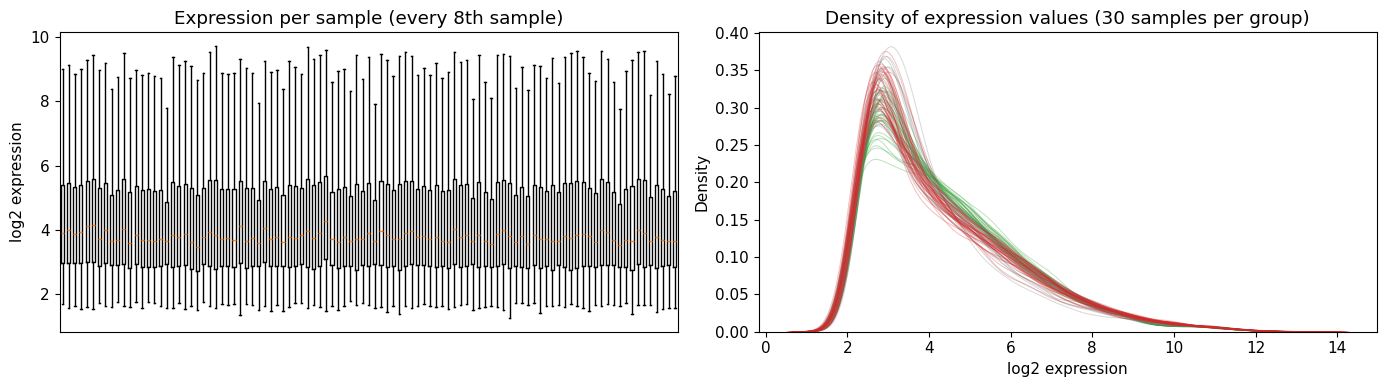

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
order = samples.sort_values("group").index
axes[0].boxplot(genes[order[::8]].values, showfliers=False)
axes[0].set_title("Expression per sample (every 8th sample)"); axes[0].set_ylabel("log2 expression"); axes[0].set_xticks([])
for g, col in zip(["Healthy", "Other_ICU", "Sepsis"], ["tab:green", "tab:grey", "tab:red"]):
    for s in samples.index[samples.group == g][:30]:
        sns.kdeplot(genes[s], ax=axes[1], color=col, alpha=0.3, lw=0.7)
axes[1].set_title("Density of expression values (30 samples per group)"); axes[1].set_xlabel("log2 expression")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "02_qc_distributions.png"), dpi=150); plt.show()

### 2.4 Outlier check (correlation with the median sample) + sex check

In [9]:
corr_to_median = genes.corrwith(genes.median(axis=1))
print(corr_to_median.describe().round(4).to_dict())
z = (corr_to_median - corr_to_median.mean()) / corr_to_median.std()
outliers = z[z < -4].index.tolist()
samples["flag_expr_outlier"] = samples.index.isin(outliers)
print("possible outliers (z < -4):", len(outliers))
print(samples.loc[outliers, ["group", "endotype_class", "mortality_event_28days"]])

# extra QC: does expression sex (XIST = female, RPS4Y1 = male) agree with recorded sex?
y_on, x_on = genes.loc["RPS4Y1"] > 5.0, genes.loc["XIST"] > 3.5
samples["expr_sex"] = np.select([y_on & ~x_on, x_on & ~y_on, y_on & x_on], ["male", "female", "mixed"], "unclear")
samples["flag_sex_mismatch"] = samples.expr_sex != samples.gender
print("\nsex mismatches:", int(samples.flag_sex_mismatch.sum()), samples.loc[samples.flag_sex_mismatch, "group"].value_counts().to_dict())

{'count': 802.0, 'mean': 0.9535, 'std': 0.0243, 'min': 0.7562, '25%': 0.9452, '50%': 0.9598, '75%': 0.969, 'max': 0.9847}
possible outliers (z < -4): 9
                group endotype_class  mortality_event_28days
GSM_ID                                                      
GSM1602973     Sepsis          Mars1                     0.0
GSM1691893     Sepsis          Mars1                     0.0
GSM1691984     Sepsis          Mars1                     1.0
GSM1692160     Sepsis          Mars1                     1.0
GSM1692235  Other_ICU            NaN                     NaN
GSM1692250  Other_ICU            NaN                     NaN
GSM1692338     Sepsis          Mars3                     0.0
GSM1692353  Other_ICU            NaN                     NaN
GSM1692354  Other_ICU            NaN                     NaN

sex mismatches: 8 {'Sepsis': 5, 'Other_ICU': 3}


**Decision: keep all arrays.** Correlations stay ≥ 0.75 and most flagged sepsis samples are Mars1 (real biology). The 8 sex mismatches come in pairs run on the same day, so they look like label swaps; they are kept, flagged, and checked in Step 7.
### 2.5–2.6 Gene-level table and low-expression genes

In [10]:
print("gene table:", genes.shape)
mean_expr = genes.mean(axis=1)
print("genes with mean expression < 3:", (mean_expr < 3).sum())

gene table: (11518, 802)
genes with mean expression < 3: 3259


### 2.7 Save

In [11]:
samples.to_csv(os.path.join(PROC, "samples_clean.csv"))
genes.to_csv(os.path.join(PROC, "genes_x_samples.csv"))
sepsis_ids = samples.index[samples.group == "Sepsis"]
genes[sepsis_ids].to_csv(os.path.join(PROC, "genes_x_sepsis479.csv"))
print("saved", len(sepsis_ids), "sepsis samples")

saved 479 sepsis samples


### 2.8 Decisions log (for the report Methods)
| Decision | Choice | Why |
|---|---|---|
| Normalisation | GEO RMA log2 values as given | Already normalised; distributions match |
| Unannotated probes | `---` row removed | Not a gene |
| Outliers | Keep all 802 | Correlation ≥ 0.75; extreme samples biologically plausible |
| Sex mismatches | Keep, flag | Likely label swaps; sensitivity check in Step 7 |
| Low expression | Drop mean < 3 for DE/ML only | Removes unexpressed genes |
| Batch | Not corrected | Run date explains ≤ 2.5% of PC variance; tested in 5.7 |

# Step 3: Describe the cohort and run the first hypothesis tests  ·  Owner P1
**Course concepts:** descriptive statistics, Shapiro–Wilk, Welch t-test, Mann–Whitney U, chi-square, Fisher's exact test.
### 3.1–3.2 Table 1

In [12]:
sep = samples[samples.group == "Sepsis"].copy()
sep["outcome"] = sep["mortality_event_28days"].map({0: "Survived", 1: "Died"})

def summarise(df):
    return pd.Series({"n": len(df), "age_median": df.age.median(),
                      "age_IQR": f"{df.age.quantile(.25):.0f}-{df.age.quantile(.75):.0f}",
                      "male_%": round(100 * (df.gender == "male").mean(), 1)})
table1 = samples.groupby("group")[["age", "gender"]].apply(summarise)
print(table1)
print("\n28-day deaths among sepsis:", int(sep.mortality_event_28days.sum()), "of", len(sep),
      f"({100*sep.mortality_event_28days.mean():.1f}%)")
table1.to_csv(os.path.join(RES, "table1.csv"))

             n  age_median age_IQR  male_%
group                                     
Healthy     42        37.0   30-63    57.1
Other_ICU  281        64.0   53-73    61.9
Sepsis     479        63.0   53-71    56.8

28-day deaths among sepsis: 114 of 479 (23.8%)


### 3.3 Is age normally distributed?

In [13]:
for g in ["Survived", "Died"]:
    w, p = stats.shapiro(sep.loc[sep.outcome == g, "age"])
    print(f"Shapiro {g}: W={w:.3f}, p={p:.2g}")

Shapiro Survived: W=0.952, p=1.6e-09
Shapiro Died: W=0.957, p=0.001


### 3.4 Did non-survivors differ in age?  (H0: equal mean / distribution)

In [14]:
a = sep.loc[sep.outcome == "Died", "age"]; b = sep.loc[sep.outcome == "Survived", "age"]
t, p_t = stats.ttest_ind(a, b, equal_var=False)
u, p_u = stats.mannwhitneyu(a, b)
print(f"Age died {a.mean():.1f} vs survived {b.mean():.1f}; Welch t={t:.2f} p={p_t:.3g}; Mann-Whitney p={p_u:.3g}")
h = samples.loc[samples.group == "Healthy", "age"]
print(f"Age healthy {h.mean():.1f} vs sepsis {sep.age.mean():.1f}; Mann-Whitney p={stats.mannwhitneyu(h, sep.age)[1]:.2g}")
SUMMARY["age_died"], SUMMARY["age_surv"], SUMMARY["age_p"] = a.mean(), b.mean(), p_t

Age died 64.5 vs survived 59.9; Welch t=3.10 p=0.0022; Mann-Whitney p=0.00699
Age healthy 46.2 vs sepsis 61.0; Mann-Whitney p=2.5e-06


### 3.5 Sex and diabetes vs death

In [15]:
ct = pd.crosstab(sep.gender, sep.outcome)
chi2, p, dof, expected = stats.chi2_contingency(ct)
print(ct); print(f"chi2={chi2:.2f}, dof={dof}, p={p:.3f}, min expected={expected.min():.1f}")
ct2 = pd.crosstab(sep.diabetes_mellitus, sep.outcome)
odds, p = stats.fisher_exact(ct2)
print(ct2); print(f"Fisher OR={odds:.2f}, p={p:.3f}")

outcome  Died  Survived
gender                 
female     46       161
male       68       204
chi2=0.36, dof=1, p=0.549, min expected=49.3
outcome            Died  Survived
diabetes_mellitus                
DM                   22        67
No_DM                68       233
Fisher OR=1.13, p=0.670


### 3.6 Figure

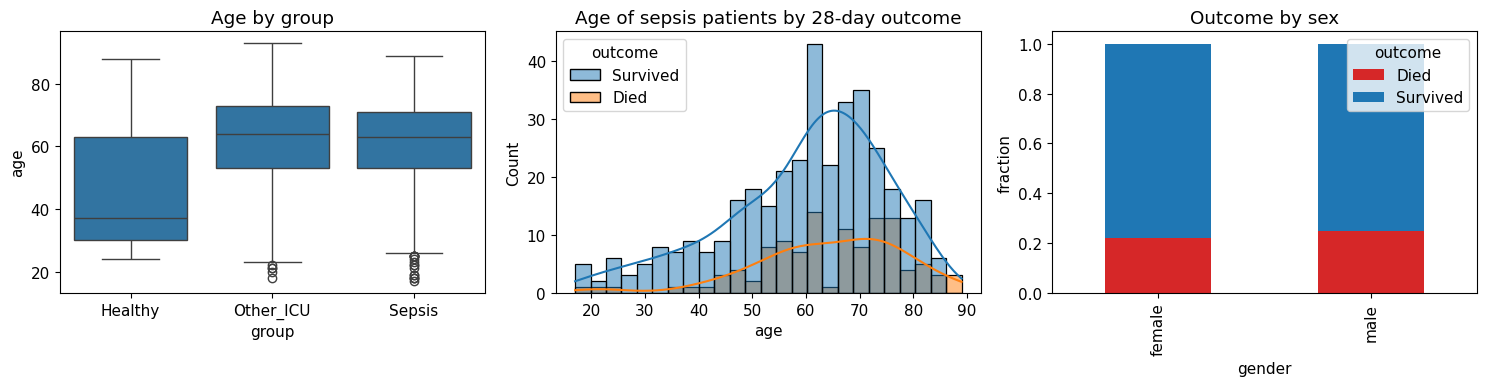

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=samples, x="group", y="age", ax=ax[0], order=["Healthy", "Other_ICU", "Sepsis"]); ax[0].set_title("Age by group")
sns.histplot(data=sep, x="age", hue="outcome", kde=True, ax=ax[1], bins=25); ax[1].set_title("Age of sepsis patients by 28-day outcome")
ct.div(ct.sum(1), axis=0).plot(kind="bar", stacked=True, ax=ax[2], color=["tab:red", "tab:blue"])
ax[2].set_title("Outcome by sex"); ax[2].set_ylabel("fraction")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "03_cohort.png"), dpi=150); plt.show()

### 3.7–3.8 Extra: QQ-plot, CAP vs HAP, Cohen's d, spread/shape measures, F-test and Levene

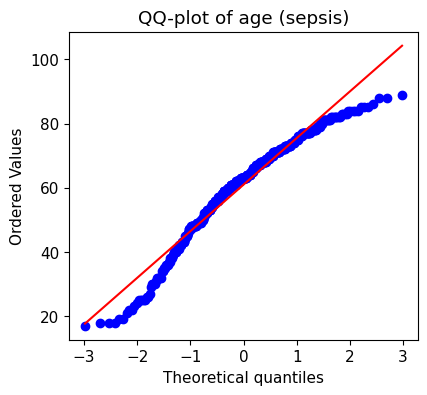

CAP vs HAP death: {'Died': {'cap': 23, 'hap': 17}, 'Survived': {'cap': 83, 'hap': 60}} chi2 p = 1.0 n = 183
Cohen's d for age = 0.32
Healthy    mean 46.2 SD 19.6 CV% 42.5 skew 0.67 kurtosis -0.95
Other_ICU  mean 61.2 SD 16.1 CV% 26.2 skew -0.73 kurtosis -0.03
Sepsis     mean 61.0 SD 14.8 CV% 24.3 skew -0.77 kurtosis 0.30
F-test: var died 183.9 vs survived 225.2; F=0.82, p=0.202; Levene p=0.379


In [17]:
fig, ax = plt.subplots(figsize=(4.5, 4)); stats.probplot(sep.age, plot=ax); ax.set_title("QQ-plot of age (sepsis)"); plt.show()
pn = sep[sep.pneumonia_diagnoses.isin(["cap", "hap"])]
print("CAP vs HAP death:", pd.crosstab(pn.pneumonia_diagnoses, pn.outcome).to_dict(), "chi2 p =",
      round(stats.chi2_contingency(pd.crosstab(pn.pneumonia_diagnoses, pn.outcome))[1], 3), "n =", len(pn))
sp = np.sqrt(((len(a)-1)*a.var() + (len(b)-1)*b.var()) / (len(a)+len(b)-2))
print(f"Cohen's d for age = {(a.mean()-b.mean())/sp:.2f}")
for g, d in samples.groupby("group"):
    x = d.age
    print(f"{g:10s} mean {x.mean():.1f} SD {x.std():.1f} CV% {100*x.std()/x.mean():.1f} skew {stats.skew(x):.2f} kurtosis {stats.kurtosis(x):.2f}")
F = a.var(ddof=1) / b.var(ddof=1)
pF = 2 * min(stats.f.cdf(F, len(a)-1, len(b)-1), 1 - stats.f.cdf(F, len(a)-1, len(b)-1))
print(f"F-test: var died {a.var():.1f} vs survived {b.var():.1f}; F={F:.2f}, p={pF:.3f}; Levene p={stats.levene(a, b)[1]:.3f}")

**Slide line:** *Non-survivors were older; sex and diabetes were not associated with death.* Welch's t-test is used by default (no F-test gate).

# Step 4: Visualise the data (PCA, UMAP, heatmap)  ·  Owner P3  ·  RQ1
**Course concepts:** variance filtering, z-scores, PCA (scree, explained variance, loadings), UMAP, clustered heatmap.
### 4.1–4.2 Top 2,000 variable genes, PCA on all 802

In [18]:
import umap
var = genes.var(axis=1).sort_values(ascending=False)
top = var.index[:2000]
X = genes.loc[top].T
Xz = StandardScaler().fit_transform(X)
pca = PCA(n_components=20, random_state=0)
pcs = pca.fit_transform(Xz)
print("matrix for PCA:", Xz.shape)
print("variance explained PC1-5:", pca.explained_variance_ratio_[:5].round(3))
print("cumulative PC1-10:", pca.explained_variance_ratio_[:10].sum().round(3))
pc = pd.DataFrame(pcs[:, :2], index=X.index, columns=["PC1", "PC2"]).join(samples[["group", "endotype_class"]])
print(pc.groupby("group")[["PC1", "PC2"]].mean().round(1))
SUMMARY["pc12_all"] = pca.explained_variance_ratio_[:2].sum()

matrix for PCA: (802, 2000)
variance explained PC1-5: [0.197 0.171 0.094 0.065 0.043]
cumulative PC1-10: 0.701
            PC1   PC2
group                
Healthy   -21.5  43.0
Other_ICU  -2.6   1.8
Sepsis      3.4  -4.8


### 4.3 Scree, PCA, UMAP

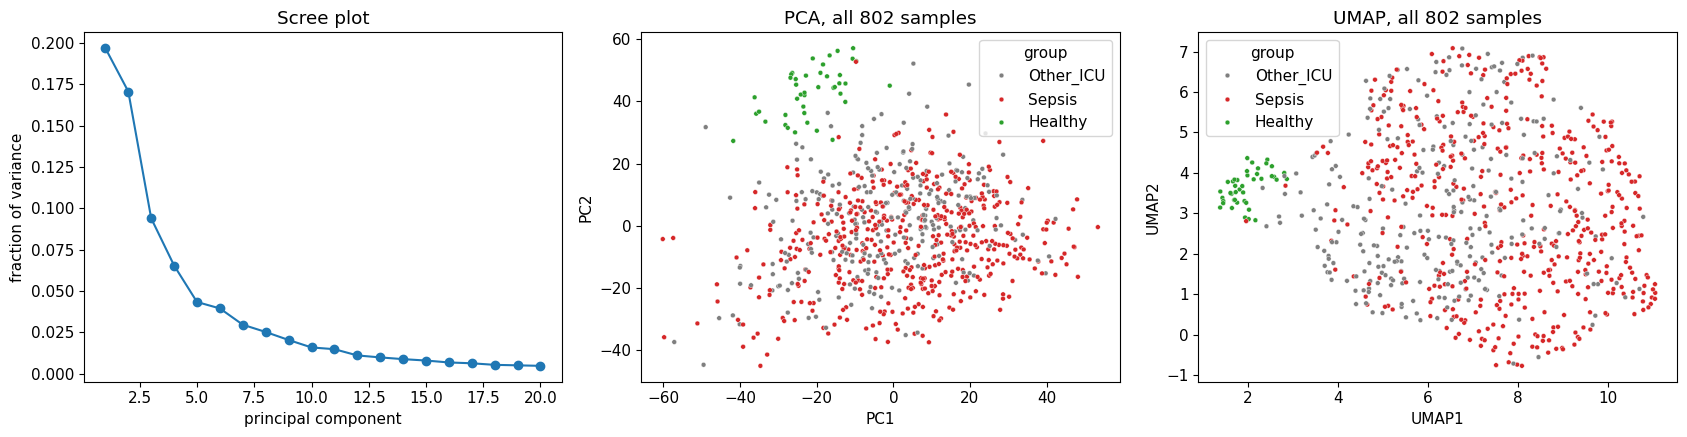

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(range(1, 21), pca.explained_variance_ratio_, "o-"); ax[0].set(xlabel="principal component", ylabel="fraction of variance", title="Scree plot")
pal = {"Healthy": "tab:green", "Other_ICU": "tab:grey", "Sepsis": "tab:red"}
sns.scatterplot(data=pc, x="PC1", y="PC2", hue="group", s=12, ax=ax[1], palette=pal); ax[1].set_title("PCA, all 802 samples")
emb = umap.UMAP(n_neighbors=15, min_dist=0.3, random_state=42).fit_transform(pcs)
um = pd.DataFrame(emb, index=X.index, columns=["UMAP1", "UMAP2"]).join(samples[["group"]])
sns.scatterplot(data=um, x="UMAP1", y="UMAP2", hue="group", s=12, ax=ax[2], palette=pal); ax[2].set_title("UMAP, all 802 samples")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "04_pca_umap_all.png"), dpi=150); plt.show()

Healthy controls separate clearly from all ICU patients; sepsis and Other_ICU overlap (Other_ICU is a mixed group, not "non-septic ICU"). Healthy controls are ~25 years younger.
### 4.4 What drives PC1? (loadings)

In [20]:
load = pd.Series(pca.components_[0], index=top).sort_values()
print("PC1 negative end:", load.index[:8].tolist())
print("PC1 positive end:", load.index[-8:].tolist())

PC1 negative end: ['ELOF1', 'ECSIT', 'SSBP3', 'CARM1', 'SLC25A38', 'PHOSPHO1', 'DPM2', 'PA2G4']
PC1 positive end: ['CD58', 'CAPZA1', 'FAR1', 'ACSL4', 'CHMP2B', 'OBFC2A', 'ATP11B', 'EIF4E3']


### 4.5 PCA inside sepsis only, by Mars endotype and by death

sepsis-only variance PC1-5: [0.226 0.122 0.099 0.069 0.05 ]


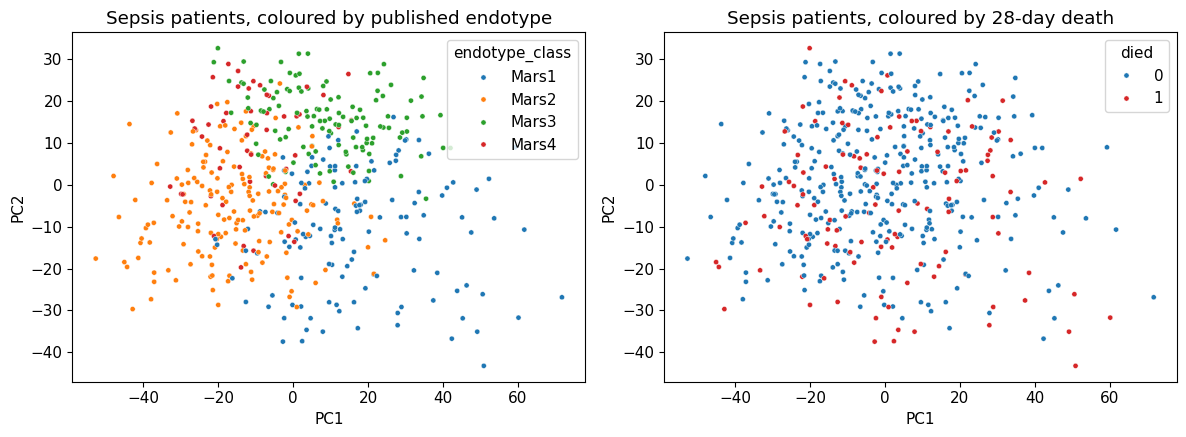

In [21]:
sep_ids = samples.index[samples.group == "Sepsis"]
top_s = genes.loc[:, sep_ids].var(axis=1).sort_values(ascending=False).index[:2000]
Xsz = StandardScaler().fit_transform(genes.loc[top_s, sep_ids].T)
ps = PCA(n_components=20, random_state=0).fit(Xsz)
pcs_s = ps.transform(Xsz)
print("sepsis-only variance PC1-5:", ps.explained_variance_ratio_[:5].round(3))
d = pd.DataFrame(pcs_s[:, :2], index=sep_ids, columns=["PC1", "PC2"]).join(samples[["endotype_class", "mortality_event_28days"]])
d["died"] = d.mortality_event_28days.astype(int)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=d, x="PC1", y="PC2", hue="endotype_class", s=14, ax=ax[0], hue_order=["Mars1", "Mars2", "Mars3", "Mars4"])
ax[0].set_title("Sepsis patients, coloured by published endotype")
sns.scatterplot(data=d, x="PC1", y="PC2", hue="died", s=14, ax=ax[1], palette={0: "tab:blue", 1: "tab:red"})
ax[1].set_title("Sepsis patients, coloured by 28-day death")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "04_pca_sepsis.png"), dpi=150); plt.show()

**Key message:** one continuous cloud ordered by endotype (Mars2 left, Mars3 top, Mars1 bottom-right). Endotypes are regions of a continuum, not islands.
### 4.6 Heatmap of the 50 most variable genes

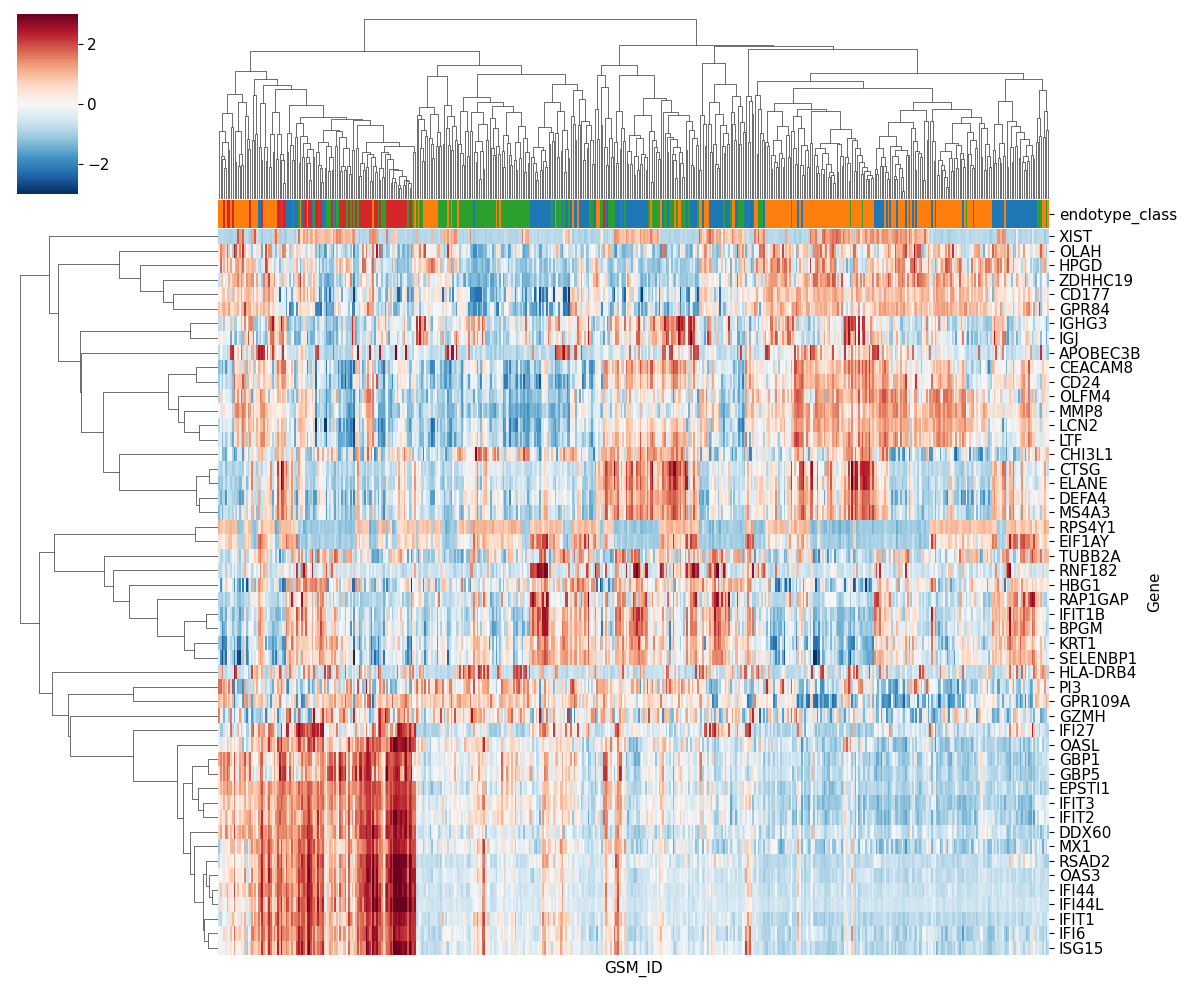

In [22]:
top50 = genes.loc[:, sep_ids].var(axis=1).sort_values(ascending=False).index[:50]
cols = samples.loc[sep_ids, "endotype_class"].map({"Mars1": "tab:blue", "Mars2": "tab:orange", "Mars3": "tab:green", "Mars4": "tab:red"})
g = sns.clustermap(genes.loc[top50, sep_ids], z_score=0, cmap="RdBu_r", vmin=-3, vmax=3, col_colors=cols,
                   xticklabels=False, yticklabels=True, figsize=(12, 10), method="average", metric="correlation")
g.savefig(os.path.join(FIG, "04_heatmap_top50.png"), dpi=120); plt.show()
np.save(os.path.join(RES, "sepsis_pcs.npy"), pcs_s)

Three gene blocks: sex genes (XIST, RPS4Y1…), interferon (IFI27, IFIT1/2/3, MX1, RSAD2…), neutrophil granules (MMP8, OLFM4, LCN2, CD177…).
### 4.7 Extra: t-SNE and MDS (supplementary pictures only, not evidence for the continuum)

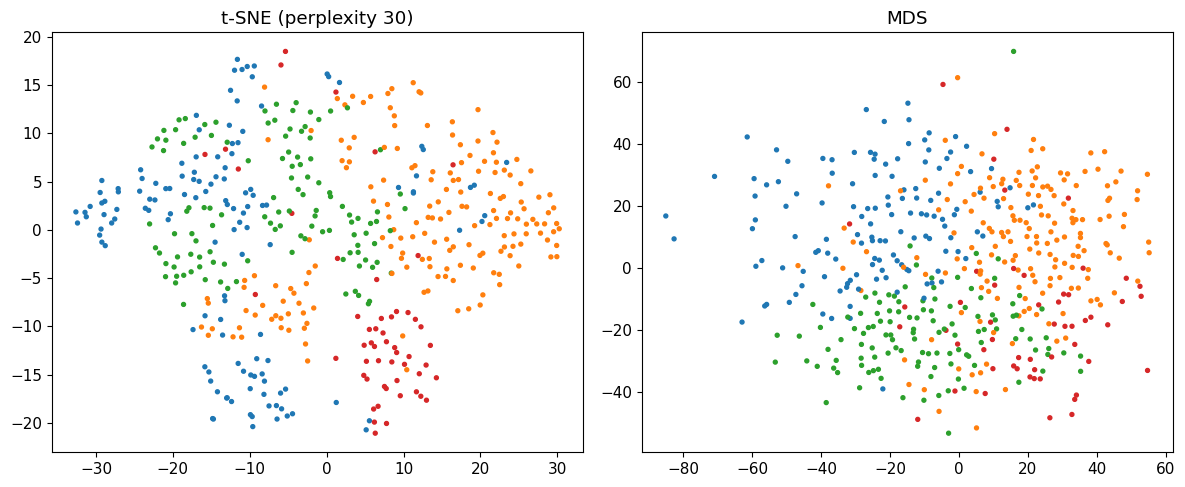

In [23]:
from sklearn.manifold import TSNE, MDS
P10 = pcs_s[:, :10]
ts = TSNE(n_components=2, perplexity=30, random_state=0).fit_transform(P10)
mdsc = MDS(n_components=2, random_state=0, n_init=1).fit_transform(P10)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(ts[:, 0], ts[:, 1], c=cols, s=8); ax[0].set_title("t-SNE (perplexity 30)")
ax[1].scatter(mdsc[:, 0], mdsc[:, 1], c=cols, s=8); ax[1].set_title("MDS")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "04_tsne_mds.png"), dpi=150); plt.show()

# Step 5: Find subtypes by clustering  ·  Owner P4  ·  RQ2
**Course concepts:** k-means, hierarchical (Ward), dendrogram, elbow, silhouette, gap statistic, ARI, contingency table. H0: no cluster structure (k = 1).
### 5.1 Input: 10 PCs of the top 2,000 genes (sepsis only)

In [24]:
from scipy.cluster.hierarchy import linkage, dendrogram
sep_expr = genes[sep_ids]
sep = samples.loc[sep_expr.columns].copy()
top = sep_expr.var(axis=1).sort_values(ascending=False).index[:2000]
Z = StandardScaler().fit_transform(sep_expr.loc[top].T)
P = PCA(n_components=10, random_state=0).fit_transform(Z)

### 5.2 Elbow and silhouette

In [25]:
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=0).fit(P)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(P, km.labels_)})
kres = pd.DataFrame(rows).set_index("k").round(3)
print(kres)

      inertia  silhouette
k                        
2  520984.026       0.190
3  462761.646       0.148
4  418008.753       0.147
5  392254.333       0.149
6  367156.062       0.145
7  348980.808       0.139
8  331957.425       0.137


### 5.3 Gap statistic

     gap     sd
1  1.056  0.020
2  1.023  0.019
3  1.046  0.020
4  1.055  0.018
5  1.071  0.016
6  1.081  0.010
7  1.082  0.015
8  1.104  0.019
gap statistic suggests k = 1


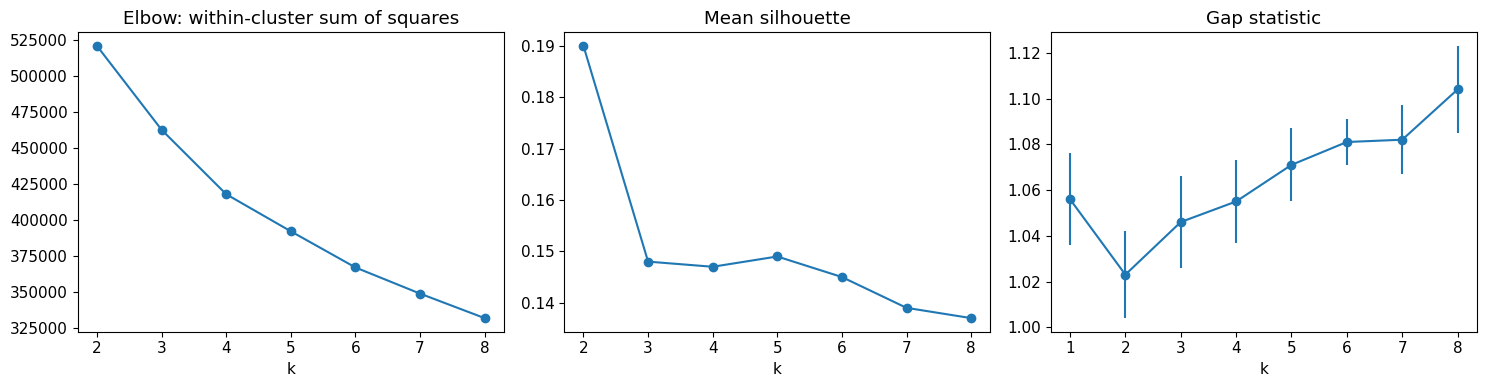

In [26]:
rng = np.random.default_rng(0)
def gap_stat(X, k, B=10):
    obs = np.log(KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_)
    lo, hi = X.min(0), X.max(0)
    ref = [np.log(KMeans(n_clusters=k, n_init=10, random_state=0).fit(rng.uniform(lo, hi, X.shape)).inertia_) for _ in range(B)]
    return np.mean(ref) - obs, np.std(ref) * np.sqrt(1 + 1 / B)
gaps = pd.DataFrame([dict(zip(["gap", "sd"], gap_stat(P, k))) for k in range(1, 9)], index=range(1, 9)).round(3)
print(gaps)
best_gap = next(k for k in range(1, 8) if gaps.gap[k] >= gaps.gap[k + 1] - gaps.sd[k + 1])
print("gap statistic suggests k =", best_gap)
SUMMARY["sil_max"], SUMMARY["gap_k"] = kres.silhouette.max(), best_gap

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(kres.index, kres.inertia, "o-"); ax[0].set(title="Elbow: within-cluster sum of squares", xlabel="k")
ax[1].plot(kres.index, kres.silhouette, "o-"); ax[1].set(title="Mean silhouette", xlabel="k")
ax[2].errorbar(gaps.index, gaps.gap, yerr=gaps.sd, fmt="o-"); ax[2].set(title="Gap statistic", xlabel="k")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "05_choose_k.png"), dpi=150); plt.show()

### 5.4 Reading these honestly
Elbow has no sharp bend, silhouette < 0.25 for every k, gap statistic picks k = 1 → **no well-separated clusters; a continuum.** We partition it with **k = 4** (the published number, so we can compare with Mars1–4; silhouette is flat across 3–5) and keep k = 2 and 3 for Step 6.
### 5.5 Final k-means and hierarchical clustering

{'C1': 98, 'C2': 137, 'C3': 115, 'C4': 129}
ARI k-means vs hierarchical: 0.336
hier4     H1  H2   H3  H4
kmeans4                  
C1         0  56   10  32
C2       106  17   14   0
C3         8   4  102   1
C4        78  29   22   0


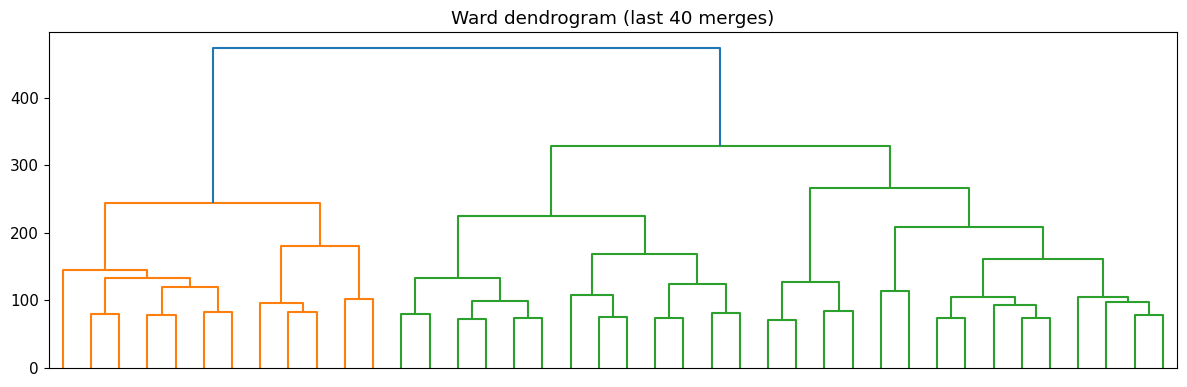

In [27]:
K = 4
km = KMeans(n_clusters=K, n_init=50, random_state=0).fit(P)
sep["kmeans4"] = ["C" + str(l + 1) for l in km.labels_]
for k in (2, 3):
    sep[f"kmeans{k}"] = ["C" + str(l + 1) for l in KMeans(n_clusters=k, n_init=50, random_state=0).fit(P).labels_]
print(sep.kmeans4.value_counts().sort_index().to_dict())
hc = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(P)
sep["hier4"] = ["H" + str(l + 1) for l in hc.labels_]
print("ARI k-means vs hierarchical:", round(adjusted_rand_score(sep.kmeans4, sep.hier4), 3))
print(pd.crosstab(sep.kmeans4, sep.hier4))
plt.figure(figsize=(12, 4)); dendrogram(linkage(P, method="ward"), no_labels=True, truncate_mode="lastp", p=40)
plt.title("Ward dendrogram (last 40 merges)"); plt.tight_layout(); plt.savefig(os.path.join(FIG, "05_dendrogram.png"), dpi=150); plt.show()

Cluster numbers are arbitrary: **C1 = the cluster that overlaps Mars1 and has the most deaths.** The next cell relabels clusters by content so C1–C4 always mean the same thing.

In [28]:
# make cluster names content-based: C1 = most Mars1, then C2 = most Mars2, C3 = most Mars3, C4 = rest
ct_m = pd.crosstab(sep.kmeans4, sep.endotype_class)
mapping, left = {}, list(ct_m.index)
for i, m in enumerate(["Mars1", "Mars2", "Mars3"], start=1):
    best = ct_m.loc[left, m].idxmax(); mapping[best] = f"C{i}"; left.remove(best)
mapping[left[0]] = "C4"
sep["kmeans4"] = sep.kmeans4.map(mapping)
print("relabelling:", mapping, "| sizes:", sep.kmeans4.value_counts().sort_index().to_dict())

relabelling: {'C1': 'C1', 'C2': 'C2', 'C3': 'C3', 'C4': 'C4'} | sizes: {'C1': 98, 'C2': 137, 'C3': 115, 'C4': 129}


### 5.6 Compare with the published Mars endotypes (RQ6 concordance)

endotype_class  Mars1  Mars2  Mars3  Mars4
kmeans4                                   
C1                 92      0      5      1
C2                 21    105      0     11
C3                 11     36     66      2
C4                  8     35     47     39
ARI k-means(4) vs Mars: 0.314
ARI hierarchical(4) vs Mars: 0.216


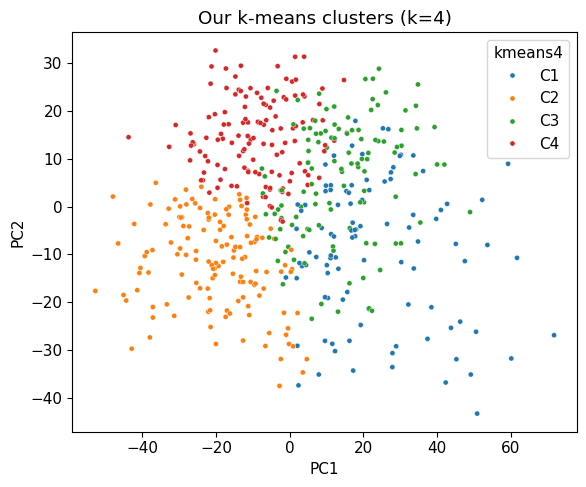

In [29]:
print(pd.crosstab(sep.kmeans4, sep.endotype_class))
ari_km = adjusted_rand_score(sep.kmeans4, sep.endotype_class)
print("ARI k-means(4) vs Mars:", round(ari_km, 3))
print("ARI hierarchical(4) vs Mars:", round(adjusted_rand_score(sep.hier4, sep.endotype_class), 3))
SUMMARY["ari_mars"] = ari_km
dd = pd.DataFrame(P[:, :2], columns=["PC1", "PC2"], index=sep.index).join(sep[["kmeans4"]])
plt.figure(figsize=(6, 5)); sns.scatterplot(data=dd, x="PC1", y="PC2", hue="kmeans4", s=14, hue_order=["C1", "C2", "C3", "C4"])
plt.title("Our k-means clusters (k=4)"); plt.tight_layout(); plt.savefig(os.path.join(FIG, "05_clusters_pca.png"), dpi=150); plt.show()
sep[["kmeans2", "kmeans3", "kmeans4", "hier4"]].to_csv(os.path.join(RES, "clusters.csv"))

### 5.7 Are the clusters driven by batch, hospital or sex?

In [30]:
sep["run_date"] = sep["title"].str.extract(r"\[(\d\d_\d\d_\d{4})")[0]
print("run dates:", sep.run_date.nunique())
r2 = [round(float(smf.ols("pc ~ C(run_date)", data=pd.DataFrame({"pc": P[:, i], "run_date": sep.run_date.values})).fit().rsquared), 3) for i in range(5)]
print("R2 of run date on PC1-5:", r2)
p_date = stats.chi2_contingency(pd.crosstab(sep.kmeans4, sep.run_date))[1]
print("k-means4 vs run date: chi2 p =", round(p_date, 3))
print("k-means4 vs hospital: chi2 p =", round(stats.chi2_contingency(pd.crosstab(sep.kmeans4, sep.endotype_cohort))[1], 5))
sex_genes = ["XIST", "RPS4Y1", "EIF1AY", "DDX3Y", "KDM5D", "UTY", "USP9Y", "ZFY"]
in_top = [g for g in sex_genes if g in top]
print("sex genes in top 2000:", in_top)
print("k-means4 vs sex: chi2 p =", round(stats.chi2_contingency(pd.crosstab(sep.kmeans4, sep.gender))[1], 3))
P_ns = PCA(n_components=10, random_state=0).fit_transform(StandardScaler().fit_transform(sep_expr.loc[[g for g in top if g not in in_top]].T))
lab_ns = KMeans(n_clusters=4, n_init=50, random_state=0).fit_predict(P_ns)
print("ARI clusters with vs without sex genes:", round(adjusted_rand_score(sep.kmeans4, lab_ns), 3))
SUMMARY["batch_r2_max"], SUMMARY["batch_p"] = max(r2), p_date

run dates: 14
R2 of run date on PC1-5: [0.025, 0.012, 0.015, 0.021, 0.014]
k-means4 vs run date: chi2 p = 0.897
k-means4 vs hospital: chi2 p = 0.00023
sex genes in top 2000: ['XIST', 'RPS4Y1', 'EIF1AY', 'DDX3Y', 'KDM5D']
k-means4 vs sex: chi2 p = 0.376
ARI clusters with vs without sex genes: 0.989


Batch: run date explains ≤ 2.5% of any PC and is unrelated to clusters. Hospital: cluster mix differs (adjusted for in Step 10). Sex genes don't drive clusters.

# Step 6: Do the clusters differ in 28-day mortality?  ·  Owner P5  ·  RQ3
**Course concepts:** chi-square, Kaplan–Meier, censoring, log-rank, Cox PH (HR, CI, PH check), Kruskal–Wallis, ANOVA, Tukey, Levene, Welch ANOVA. H0: death rate is the same in every cluster.
### 6.1–6.2 Death rate per cluster + chi-square

In [31]:
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import multivariate_logrank_test, proportional_hazard_test
sep["died"] = sep.mortality_event_28days.astype(int)
sep["days"] = sep.time_to_event_28days
rows = []
for col in ["kmeans2", "kmeans3", "kmeans4", "hier4", "endotype_class"]:
    ct = pd.crosstab(sep[col], sep.died)
    chi2, p, dof, exp = stats.chi2_contingency(ct)
    rows.append({"clustering": col, "death rate": (ct[1] / ct.sum(1)).round(3).to_dict(), "chi2": round(chi2, 2), "dof": dof, "p": round(p, 4), "min expected": round(exp.min(), 1)})
mort = pd.DataFrame(rows); print(mort.to_string(index=False))
mort.to_csv(os.path.join(RES, "06_mortality_chi2.csv"), index=False)
rate4 = sep.groupby("kmeans4").died.mean()
SUMMARY["c1_rate"], SUMMARY["c4_rate"] = rate4["C1"], rate4.min()
SUMMARY["chi2_p_k4"] = mort.loc[mort.clustering == "kmeans4", "p"].iloc[0]

    clustering                                                       death rate  chi2  dof      p  min expected
       kmeans2                                       {'C1': 0.242, 'C2': 0.235}  0.00    1 0.9513          50.2
       kmeans3                          {'C1': 0.268, 'C2': 0.165, 'C3': 0.283}  7.51    2 0.0234          33.8
       kmeans4               {'C1': 0.327, 'C2': 0.263, 'C3': 0.2, 'C4': 0.178}  8.15    3 0.0430          23.3
         hier4             {'H1': 0.224, 'H2': 0.302, 'H3': 0.176, 'H4': 0.394} 10.19    3 0.0170           7.9
endotype_class {'Mars1': 0.341, 'Mars2': 0.216, 'Mars3': 0.178, 'Mars4': 0.189} 11.24    3 0.0105          12.6


k = 2 has no mortality difference; at k = 3–4 one high-risk group appears. With Bonferroni over the 4 k-means tests (0.05/4), k = 4 alone is borderline: say so; Steps 9–10 give the support.
### 6.3 Kaplan–Meier and log-rank

kmeans4 log-rank chi2 = 9.02 p = 0.0291
endotype_class log-rank chi2 = 12.18 p = 0.0068


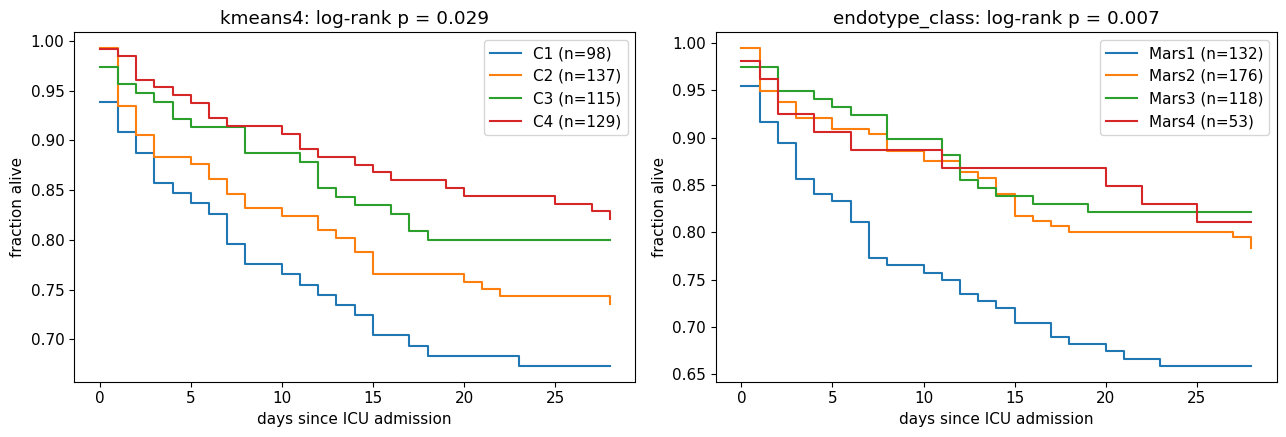

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a_, col in zip(ax, ["kmeans4", "endotype_class"]):
    for g in sorted(sep[col].unique()):
        m = sep[col] == g
        KaplanMeierFitter().fit(sep.days[m], sep.died[m], label=f"{g} (n={m.sum()})").plot_survival_function(ax=a_, ci_show=False)
    lr = multivariate_logrank_test(sep.days, sep[col], sep.died)
    a_.set_title(f"{col}: log-rank p = {lr.p_value:.3f}"); a_.set_xlabel("days since ICU admission"); a_.set_ylabel("fraction alive")
    print(col, "log-rank chi2 =", round(lr.test_statistic, 2), "p =", round(lr.p_value, 4))
    if col == "kmeans4": SUMMARY["logrank_p"] = lr.p_value
plt.tight_layout(); plt.savefig(os.path.join(FIG, "06_kaplan_meier.png"), dpi=150); plt.show()

### 6.4 Hazard ratio (Cox) and proportional-hazards check

In [33]:
sep["high_risk"] = (sep.kmeans4 == "C1").astype(int)
cph = CoxPHFitter().fit(sep[["days", "died", "high_risk"]], duration_col="days", event_col="died")
s = cph.summary.loc["high_risk"]
print(f"Cox: C1 vs rest HR={s['exp(coef)']:.2f} (95% CI {s['exp(coef) lower 95%']:.2f}-{s['exp(coef) upper 95%']:.2f}) p={s['p']:.4f}")
SUMMARY["hr"], SUMMARY["hr_lo"], SUMMARY["hr_hi"] = s["exp(coef)"], s["exp(coef) lower 95%"], s["exp(coef) upper 95%"]
d1 = sep[["days", "died", "high_risk"]]
print(proportional_hazard_test(cph, d1, time_transform="rank").summary[["test_statistic", "p"]].round(3))
d2 = sep[["days", "died", "high_risk", "age"]]
cph2 = CoxPHFitter().fit(d2, duration_col="days", event_col="died")
print(proportional_hazard_test(cph2, d2, time_transform="rank").summary[["test_statistic", "p"]].round(3))

Cox: C1 vs rest HR=1.66 (95% CI 1.11-2.50) p=0.0146
           test_statistic      p
high_risk           1.048  0.306
           test_statistic      p
age                 0.246  0.620
high_risk           1.077  0.299


Compare: Scicluna's Mars1 HR = 1.86 (1.21–2.86). Caution: C1 was chosen *because* it had the most deaths ("selection then test"); the 4-group log-rank test does not have this problem. PH p > 0.05 → no evidence the assumption is violated.
### 6.5 Age across clusters: Kruskal–Wallis, ANOVA + Tukey, Levene, Welch's ANOVA

In [34]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway
import itertools
cs = ["C1", "C2", "C3", "C4"]
groups = [sep.age[sep.kmeans4 == g] for g in cs]
print("age by cluster:", sep.groupby("kmeans4").age.median().to_dict(), "Kruskal p =", round(stats.kruskal(*groups)[1], 4))
sep.to_csv(os.path.join(RES, "sepsis_with_clusters.csv"))
E_all = genes.loc[:, sep.index]
print("ANOVA age ~ cluster: F=%.2f p=%.3f" % stats.f_oneway(*groups))
print(pairwise_tukeyhsd(sep.age, sep.kmeans4).summary())
ca1 = [E_all.loc["CA1", sep.kmeans4 == c] for c in cs]
print("ANOVA CA1 ~ cluster: F=%.1f p=%.2g" % stats.f_oneway(*ca1))
print("Levene age:", round(stats.levene(*groups).pvalue, 3), "| Levene CA1: %.2g" % stats.levene(*ca1).pvalue)
r = anova_oneway(E_all.loc["CA1"].values, sep.kmeans4.values, use_var="unequal")
print("Welch ANOVA CA1: F=%.1f p=%.2g" % (r.statistic, r.pvalue))
pairs = list(itertools.combinations(cs, 2))
pv = [stats.ttest_ind(E_all.loc["CA1", sep.kmeans4 == x], E_all.loc["CA1", sep.kmeans4 == y], equal_var=False).pvalue for x, y in pairs]
for (x, y), p in zip(pairs, multipletests(pv, method="holm")[1]):
    print(x, y, "Holm-adjusted p = %.2g" % p)

age by cluster: {'C1': 62.0, 'C2': 64.0, 'C3': 63.0, 'C4': 63.0} Kruskal p = 0.8678
ANOVA age ~ cluster: F=0.65 p=0.583
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
    C1     C2  -0.5001 0.9942 -5.5513 4.5512  False
    C1     C3   0.6554 0.9885 -4.5935 5.9043  False
    C1     C4  -1.8908 0.7762  -7.007 3.2253  False
    C2     C3   1.1554 0.9267 -3.6733 5.9841  False
    C2     C4  -1.3908   0.87 -6.0749 3.2933  False
    C3     C4  -2.5462 0.5375 -7.4428 2.3503  False
---------------------------------------------------
ANOVA CA1 ~ cluster: F=93.7 p=1.2e-47
Levene age: 0.326 | Levene CA1: 3.9e-18
Welch ANOVA CA1: F=222.5 p=8.8e-71
C1 C2 Holm-adjusted p = 6.1e-37
C1 C3 Holm-adjusted p = 7.9e-35
C1 C4 Holm-adjusted p = 3.3e-43
C2 C3 Holm-adjusted p = 0.0012
C2 C4 Holm-adjusted p = 0.22
C3 C4 Holm-adjusted p = 3.3e-06


Age does not differ between clusters → age cannot explain C1's mortality. CA1 (red-cell gene) has unequal variances → Welch's ANOVA + Holm is the primary result; plain ANOVA/Tukey only for age.

---
# CHECKPOINT 1: mid-term presentation material (manual §15)
Steps 1–6 above + 5.7 batch + 9.7 continuum = the presentation. Slide plan: 1 Title · 2 Problem + RQs · 3 Data/QC/batch · 4 PCA/UMAP · 5 Clusters + Mars crosstab · 6 Mortality KM · 7 Continuum vs clusters (AIC table, Step 9.7) · 8 Next steps + limitations.

# Step 7: Differential expression with FDR correction  ·  Owner P1  ·  RQ4
**Course concepts:** Welch t-test, Mann–Whitney, multiple testing, Bonferroni, Benjamini–Hochberg, p-value histogram, permutation, volcano plot, log2FC. H0 per gene: equal mean in the two groups.
### 7.1–7.2 Filter and the test function

In [35]:
E = genes.loc[:, sep.index]
E = E[E.mean(axis=1) >= 3]
print("genes tested:", E.shape[0])
def de_test(E, in_group):
    a, b = E.loc[:, in_group], E.loc[:, ~in_group]
    t, p = stats.ttest_ind(a, b, axis=1, equal_var=False)
    res = pd.DataFrame({"mean_in": a.mean(1), "mean_out": b.mean(1), "t": t, "p": p}, index=E.index)
    res["log2FC"] = res.mean_in - res.mean_out
    res["p_MWU"] = stats.mannwhitneyu(a, b, axis=1).pvalue
    res["FDR"] = multipletests(res.p, method="fdr_bh")[1]
    res["bonferroni"] = np.minimum(res.p * len(res), 1)
    return res.sort_values("p")

genes tested: 8200


### 7.3 Died vs survived

In [37]:
died = (sep.died == 1).values
res = de_test(E, died)
print("raw p<0.05:", (res.p < 0.05).sum(), "| FDR<0.05:", (res.FDR < 0.05).sum(), "| FDR<0.01:", (res.FDR < 0.01).sum(),
      "| Bonferroni<0.05:", (res.bonferroni < 0.05).sum())
sig = res[res.FDR < 0.05]
print("up in non-survivors:", (sig.log2FC > 0).sum(), " down:", (sig.log2FC < 0).sum())
print("max |log2FC| among FDR<0.05:", round(float(sig.log2FC.abs().max()), 2))
print(res.head(12)[["log2FC", "p", "FDR", "p_MWU"]].to_string(float_format="%.3g"))
print("agreement t-test vs Mann-Whitney (both p<0.01):", ((res.p < 0.01) & (res.p_MWU < 0.01)).sum(), "of", (res.p < 0.01).sum())
res.to_csv(os.path.join(RES, "DE_died_vs_survived.csv"))
SUMMARY["n_de"], SUMMARY["pct_down"] = len(sig), 100 * (sig.log2FC < 0).mean()

raw p<0.05: 2371 | FDR<0.05: 680 | FDR<0.01: 66 | Bonferroni<0.05: 14
up in non-survivors: 116  down: 564
max |log2FC| among FDR<0.05: 0.97
            log2FC        p      FDR    p_MWU
Gene                                         
TNFSF12     -0.228 2.24e-07 0.000873 1.94e-07
TRIM27      -0.353 3.76e-07 0.000873 1.14e-07
TNFRSF8     -0.253 4.12e-07 0.000873 2.39e-06
CX3CR1      -0.813 4.26e-07 0.000873 4.12e-07
TUBG2        0.467 6.02e-07 0.000987    6e-08
AMICA1      -0.318 1.85e-06  0.00253 2.24e-06
NCRNA00188   0.344  3.2e-06  0.00314 1.57e-06
ZNF862      -0.236 3.26e-06  0.00314 1.13e-06
CALHM2       -0.33 3.81e-06  0.00314 5.34e-06
INTS3       -0.134 3.92e-06  0.00314 3.58e-05
TCHP        -0.236 4.62e-06  0.00314 1.24e-05
GAB3         -0.32 4.67e-06  0.00314  1.7e-05
agreement t-test vs Mann-Whitney (both p<0.01): 936 of 1098


### 7.4 Sanity check: shuffle the labels (permutation) + sensitivity without flagged samples

In [38]:
rng = np.random.default_rng(1)
shuf = de_test(E, rng.permutation(died))
print("shuffled labels -> FDR<0.05:", (shuf.FDR < 0.05).sum(), "| raw p<0.05:", (shuf.p < 0.05).sum())
SUMMARY["n_shuffled"] = (shuf.FDR < 0.05).sum()
flag = (sep.flag_sex_mismatch | sep.flag_expr_outlier | ((sep.died == 0) & (sep.days < 28))).values
res_s = de_test(E.loc[:, ~flag], died[~flag])
print(f"without {flag.sum()} flagged samples: {(res_s.FDR < 0.05).sum()} genes FDR<0.05; "
      f"t-statistic correlation with main = {np.corrcoef(res.t, res_s.t.reindex(res.index))[0, 1]:.3f}")

shuffled labels -> FDR<0.05: 0 | raw p<0.05: 239
without 12 flagged samples: 251 genes FDR<0.05; t-statistic correlation with main = 0.984


### 7.5 Volcano and p-value histogram

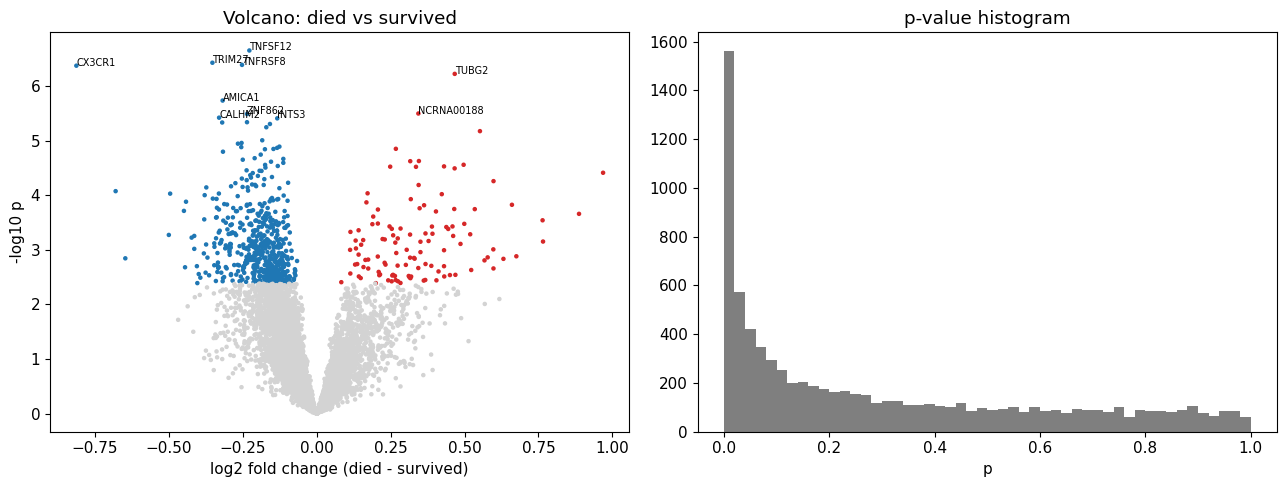

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
c = np.where((res.FDR < 0.05) & (res.log2FC > 0), "tab:red", np.where((res.FDR < 0.05) & (res.log2FC < 0), "tab:blue", "lightgrey"))
ax[0].scatter(res.log2FC, -np.log10(res.p), c=c, s=5)
for g in res.index[:10]:
    ax[0].annotate(g, (res.log2FC[g], -np.log10(res.p[g])), fontsize=7)
ax[0].set(xlabel="log2 fold change (died - survived)", ylabel="-log10 p", title="Volcano: died vs survived")
ax[1].hist(res.p, bins=50, color="tab:grey"); ax[1].set(title="p-value histogram", xlabel="p")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "07_volcano_mortality.png"), dpi=150); plt.show()

### 7.6 Marker genes of each cluster (cluster vs rest)

In [40]:
for cl in cs:
    r = de_test(E, (sep.kmeans4 == cl).values)
    s_ = r[(r.FDR < 0.05) & (r.log2FC.abs() > 1)]
    print(f"{cl}: FDR<0.05 & |log2FC|>1: {len(s_)} | top up {r[r.log2FC > 0].head(6).index.tolist()} | top down {r[r.log2FC < 0].head(6).index.tolist()}")
    r.to_csv(os.path.join(RES, f"DE_{cl}_vs_rest.csv"))

C1: FDR<0.05 & |log2FC|>1: 286 | top up ['GLRX5', 'EPB42', 'CA1', 'SELENBP1', 'BNIP3L', 'AHSP'] | top down ['DLGAP4', 'SAP30BP', 'OS9', 'COPS7A', 'KDM4A', 'SLC25A11']
C2: FDR<0.05 & |log2FC|>1: 232 | top up ['ATP11B', 'LDHA', 'MMADHC', 'GYG1', 'SLC25A40', 'PCMT1'] | top down ['MAP2K7', 'C14orf159', 'SQSTM1', 'RPS6KA5', 'WDR81', 'CYB561']
C3: FDR<0.05 & |log2FC|>1: 127 | top up ['GNAI2', 'ARHGEF2', 'FGD3', 'SP1', 'RNPEPL1', 'RNASEK'] | top down ['ETNK1', 'TBC1D23', 'TMX1', 'TMX3', 'ATG5', 'ATAD2B']
C4: FDR<0.05 & |log2FC|>1: 91 | top up ['PPTC7', 'FGL2', 'CTSS', 'QKI', 'SMCHD1', 'ITM2B'] | top down ['OSTalpha', 'SFXN1', 'CYB5R3', 'ICA1', 'ZDHHC3', 'PGM2L1']


C1's top genes (EPB42, CA1, AHSP, GLRX5, SELENBP1…) are red-cell / erythroid genes, matching Mars1's "increased haem biosynthesis".
### 7.7 Extra: why Welch? An F-test on every gene

In [41]:
va = E.loc[:, died].var(axis=1, ddof=1); vb = E.loc[:, ~died].var(axis=1, ddof=1)
Fg = va / vb; dfa, dfb = died.sum() - 1, (~died).sum() - 1
pg = 2 * np.minimum(stats.f.cdf(Fg, dfa, dfb), 1 - stats.f.cdf(Fg, dfa, dfb))
print(f"genes with unequal variance (F-test p<0.05): {(pg < 0.05).sum()} of {len(pg)} (expected by chance ~{0.05*len(pg):.0f})")

genes with unequal variance (F-test p<0.05): 1244 of 8200 (expected by chance ~410)


# Step 8: Pathway enrichment  ·  Owner P2  ·  RQ5
**Course concepts:** over-representation analysis, Fisher's exact / hypergeometric, background universe, FDR on pathways, GSEA (NES, permutation). H0: DE genes are not enriched for any pathway.
### 8.1 Load gene sets

In [42]:
import gseapy as gp
def read_gmt(path):
    sets = {}
    for line in open(path):
        parts = line.rstrip("\n").split("\t")
        sets[parts[0].replace("HALLMARK_", "")] = set(parts[2:])
    return sets
hallmark = read_gmt(GMT)
print(len(hallmark), "gene sets, e.g.", list(hallmark)[:4])

50 gene sets, e.g. ['TNFA_SIGNALING_VIA_NFKB', 'HYPOXIA', 'CHOLESTEROL_HOMEOSTASIS', 'MITOTIC_SPINDLE']


### 8.2 ORA with Fisher's exact test (universe = the 8,200 tested genes)

In [43]:
def ora(gene_list, universe, sets, min_size=10):
    gene_list = set(gene_list) & universe
    rows = []
    for name, s in sets.items():
        s = s & universe
        if len(s) < min_size: continue
        a = len(gene_list & s); b = len(gene_list - s); c = len(s - gene_list); d = len(universe) - a - b - c
        odds, p = stats.fisher_exact([[a, b], [c, d]], alternative="greater")
        rows.append({"set": name, "overlap": a, "set_size": len(s), "odds_ratio": odds, "p": p, "genes": ",".join(sorted(gene_list & s)[:8])})
    r = pd.DataFrame(rows); r["FDR"] = multipletests(r.p, method="fdr_bh")[1]
    return r.sort_values("p")
de = res
universe = set(de.index)
up = de.index[(de.FDR < 0.05) & (de.log2FC > 0)]
down = de.index[(de.FDR < 0.05) & (de.log2FC < 0)]
for name, lst in [("UP in died", up), ("DOWN in died", down)]:
    r = ora(lst, universe, hallmark)
    print(f"\n{name} ({len(lst)} genes)")
    print(r.head(6)[["set", "overlap", "set_size", "odds_ratio", "p", "FDR"]].to_string(float_format="%.3g", index=False))
    r.to_csv(os.path.join(RES, f"ORA_{name.split()[0]}_in_died.csv"), index=False)


UP in died (116 genes)
                    set  overlap  set_size  odds_ratio        p      FDR
        HEME_METABOLISM       27       160        18.1 3.23e-22 1.58e-20
                HYPOXIA        8       115        5.52 0.000211  0.00518
ESTROGEN_RESPONSE_EARLY        6        80         5.9 0.000903   0.0147
       MTORC1_SIGNALING        7       148        3.62   0.0049   0.0601
 ESTROGEN_RESPONSE_LATE        5        84        4.56   0.0066   0.0647
    IL2_STAT5_SIGNALING        6       124        3.68  0.00813   0.0664

DOWN in died (564 genes)
                      set  overlap  set_size  odds_ratio        p      FDR
INTERFERON_GAMMA_RESPONSE       28       163         2.9 5.26e-06 0.000258
INTERFERON_ALPHA_RESPONSE       14        77        3.06 0.000668   0.0164
      ALLOGRAFT_REJECTION       17       129        2.09  0.00701    0.115
          NOTCH_SIGNALING        4        17        4.19   0.0257    0.315
               COMPLEMENT       12       126        1.43    0.15

### 8.3 GSEA (all genes ranked by t, 1,000 permutations)

                             Term   NES  NOM p-val  FDR q-val
        INTERFERON_ALPHA_RESPONSE    -2          0    0.00056
        INTERFERON_GAMMA_RESPONSE -1.92          0    0.00056
              ALLOGRAFT_REJECTION -1.86          0   0.000747
            INFLAMMATORY_RESPONSE -1.63          0     0.0123
                       COMPLEMENT -1.55          0      0.028
          IL6_JAK_STAT3_SIGNALING  -1.5     0.0154     0.0452
                  NOTCH_SIGNALING -1.35      0.113       0.19
       WNT_BETA_CATENIN_SIGNALING -1.33      0.133      0.203
            XENOBIOTIC_METABOLISM  1.25     0.0244      0.246
           ESTROGEN_RESPONSE_LATE  1.33     0.0143      0.163
EPITHELIAL_MESENCHYMAL_TRANSITION   1.4       0.05      0.119
                       GLYCOLYSIS   1.4          0      0.131
                 MTORC1_SIGNALING  1.55          0     0.0594
                   G2M_CHECKPOINT  1.73          0     0.0233
          CHOLESTEROL_HOMEOSTASIS  1.98          0    0.00171
        

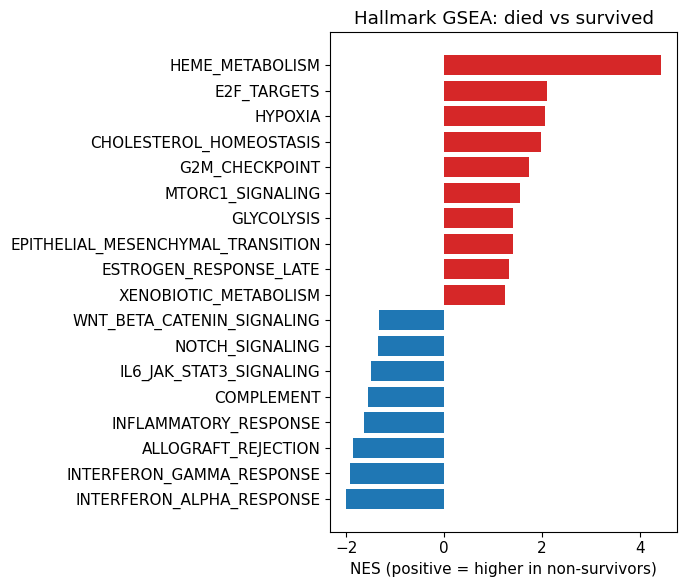

In [44]:
rnk = de["t"].sort_values(ascending=False)
pre = gp.prerank(rnk=rnk, gene_sets=GMT, permutation_num=1000, min_size=15, max_size=500, seed=7, threads=4, outdir=None, verbose=False)
g = pre.res2d[["Term", "NES", "NOM p-val", "FDR q-val"]].copy()
g["Term"] = g.Term.str.replace("HALLMARK_", "")
g[["NES", "NOM p-val", "FDR q-val"]] = g[["NES", "NOM p-val", "FDR q-val"]].astype(float)
g = g.sort_values("NES")
print(g[g["FDR q-val"] < 0.25].to_string(float_format="%.3g", index=False))
g.to_csv(os.path.join(RES, "GSEA_mortality.csv"), index=False)
plt.figure(figsize=(7, 6)); gg = g[g["FDR q-val"] < 0.25]
plt.barh(gg.Term, gg.NES, color=np.where(gg.NES > 0, "tab:red", "tab:blue"))
plt.xlabel("NES (positive = higher in non-survivors)"); plt.title("Hallmark GSEA: died vs survived")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "08_gsea_mortality.png"), dpi=150); plt.show()
SUMMARY["gsea_up"] = gg[gg.NES > 0].sort_values("NES", ascending=False).Term.head(4).tolist()
SUMMARY["gsea_down"] = gg[gg.NES < 0].Term.head(4).tolist()

Non-survivors: ↑ haem metabolism, E2F/G2M, hypoxia, mTORC1; ↓ interferon α/γ, inflammatory, complement, allograft rejection (T-cell/HLA).
### 8.4 GSEA for each cluster

C1: up ['HEME_METABOLISM', 'MYOGENESIS'] | down ['IL6_JAK_STAT3_SIGNALING', 'INFLAMMATORY_RESPONSE', 'APICAL_JUNCTION']
C2: up ['PROTEIN_SECRETION', 'ANDROGEN_RESPONSE', 'MTORC1_SIGNALING', 'PI3K_AKT_MTOR_SIGNALING'] | down ['HEME_METABOLISM', 'INTERFERON_ALPHA_RESPONSE', 'MYC_TARGETS_V2', 'MYOGENESIS']
C3: up [] | down ['PROTEIN_SECRETION', 'E2F_TARGETS', 'MYC_TARGETS_V1']
C4: up ['INTERFERON_ALPHA_RESPONSE', 'INTERFERON_GAMMA_RESPONSE', 'ALLOGRAFT_REJECTION', 'TNFA_SIGNALING_VIA_NFKB'] | down ['HEME_METABOLISM', 'COAGULATION', 'MYOGENESIS', 'EPITHELIAL_MESENCHYMAL_TRANSITION']


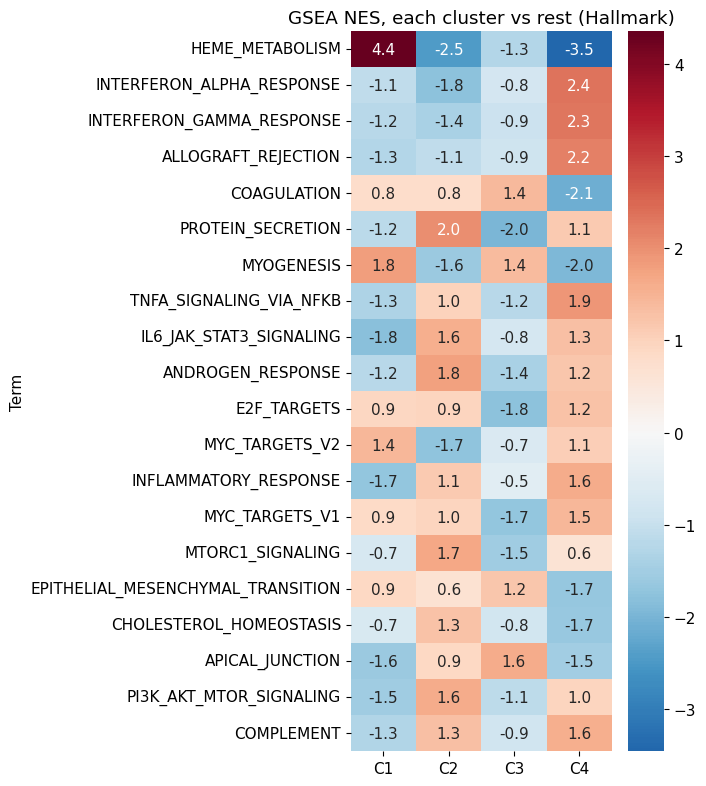

In [45]:
nes = {}
for cl in cs:
    dcl = pd.read_csv(os.path.join(RES, f"DE_{cl}_vs_rest.csv"), index_col=0)
    p_ = gp.prerank(rnk=dcl["t"].sort_values(ascending=False), gene_sets=GMT, permutation_num=500, min_size=15, max_size=500,
                    seed=7, threads=4, outdir=None, verbose=False).res2d
    p_["Term"] = p_.Term.str.replace("HALLMARK_", "")
    nes[cl] = p_.set_index("Term")["NES"].astype(float)
    p_["FDR q-val"] = p_["FDR q-val"].astype(float); p_["NES"] = p_["NES"].astype(float)
    tp = p_[p_["FDR q-val"] < 0.05].sort_values("NES")
    print(f"{cl}: up {tp[tp.NES > 0].Term.tail(4).tolist()[::-1]} | down {tp[tp.NES < 0].Term.head(4).tolist()}")
nes = pd.DataFrame(nes)
keep = nes.abs().max(1).sort_values(ascending=False).index[:20]
plt.figure(figsize=(7, 8)); sns.heatmap(nes.loc[keep], cmap="RdBu_r", center=0, annot=True, fmt=".1f")
plt.title("GSEA NES, each cluster vs rest (Hallmark)"); plt.tight_layout()
plt.savefig(os.path.join(FIG, "08_cluster_gsea_heatmap.png"), dpi=150); plt.show()

Expected match: C1 ↑ haem, ↓ IL-6/inflammatory (Mars1, SRS1-like) · C2 ↑ mTORC1/IL-6 (Mars2, inflammopathic) · C3 quiet (Mars3, adaptive) · C4 ↑ interferon (Mars4).
### 8.5 Optional: Enrichr (GO, KEGG); needs internet, skipped automatically if it fails

In [46]:
try:
    enr = gp.enrichr(gene_list=list(down), gene_sets=["GO_Biological_Process_2023", "KEGG_2021_Human"], background=list(universe), outdir=None)
    display(enr.results.sort_values("Adjusted P-value").head(10)[["Gene_set", "Term", "Overlap", "Adjusted P-value"]])
except Exception as e:
    print("Enrichr not reachable, skipped:", type(e).__name__)

Enrichr not reachable, skipped: JSONDecodeError


# Step 9: Robustness and comparison with the published endotypes  ·  Owner P4  ·  RQ6
**Course concepts:** subsampling stability, ARI, sensitivity analysis, replication, negative control. H0: clusters unrelated to Mars (ARI ≈ 0).
### 9.1 A reusable clustering function

In [47]:
def cluster(E_, n_genes=2000, k=4, n_pcs=10, seed=0):
    t_ = E_.var(axis=1).sort_values(ascending=False).index[:n_genes]
    P_ = PCA(n_components=n_pcs, random_state=0).fit_transform(StandardScaler().fit_transform(E_.loc[t_].T))
    return KMeans(n_clusters=k, n_init=20, random_state=seed).fit_predict(P_)
Efull = genes.loc[:, sep.index]
ref = sep.kmeans4.values

### 9.2 Stability under resampling (50 × 80% subsamples)

subsample ARI: mean 0.830, 5th-95th pct 0.661-0.956


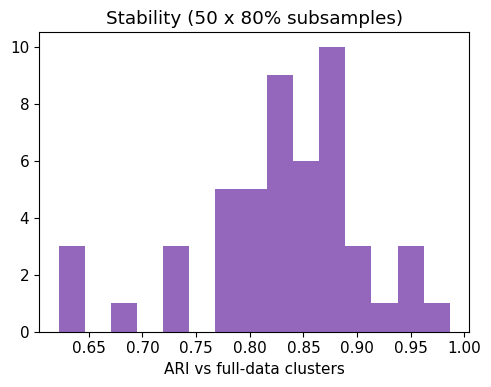

In [48]:
rng = np.random.default_rng(0); aris = []
for b_ in range(50):
    idx = np.sort(rng.choice(len(sep), size=int(0.8 * len(sep)), replace=False))
    aris.append(adjusted_rand_score(ref[idx], cluster(Efull.iloc[:, idx], seed=b_)))
aris = np.array(aris)
print(f"subsample ARI: mean {aris.mean():.3f}, 5th-95th pct {np.percentile(aris, 5):.3f}-{np.percentile(aris, 95):.3f}")
SUMMARY["boot_ari"] = aris.mean()
plt.figure(figsize=(5, 4)); plt.hist(aris, bins=15, color="tab:purple"); plt.xlabel("ARI vs full-data clusters")
plt.title("Stability (50 x 80% subsamples)"); plt.tight_layout(); plt.savefig(os.path.join(FIG, "09_bootstrap.png"), dpi=150); plt.show()

### 9.3 Sensitivity to the number of genes (500–5,000)

In [49]:
rows = []
for n in [500, 1000, 2000, 5000]:
    lab = cluster(Efull, n_genes=n); ct = pd.crosstab(lab, sep.died)
    rows.append({"n_genes": n, "ARI_vs_ours": adjusted_rand_score(ref, lab), "ARI_vs_Mars": adjusted_rand_score(sep.endotype_class, lab),
                 "max_death_rate": (ct[1] / ct.sum(1)).max(), "chi2_p": stats.chi2_contingency(ct)[1]})
sens = pd.DataFrame(rows).round(3); print(sens.to_string(index=False))
SUMMARY["ari_mars_500"] = sens.loc[sens.n_genes == 500, "ARI_vs_Mars"].iloc[0]

 n_genes  ARI_vs_ours  ARI_vs_Mars  max_death_rate  chi2_p
     500        0.413        0.618           0.345   0.013
    1000        0.379        0.592           0.356   0.011
    2000        1.000        0.314           0.327   0.043
    5000        0.552        0.280           0.340   0.012


**Decision (fixed before looking): 2,000 genes is the main analysis, 500 is a sensitivity analysis.** The exact partition moves, but every version has a high-risk cluster (~33–36%) with significant χ².
### 9.4 Replication across the two hospitals

In [50]:
for coh in ["discovery", "validation"]:
    s_ = sep[sep.endotype_cohort == coh]; ct = pd.crosstab(s_.kmeans4, s_.died)
    print(coh, "n =", len(s_), "death rate", (ct[1] / ct.sum(1)).round(3).to_dict(), "chi2 p =", round(stats.chi2_contingency(ct)[1], 3))
for coh in ["discovery", "validation"]:
    m = (sep.endotype_cohort == coh).values
    print(coh, "own clustering ARI vs Mars:", round(adjusted_rand_score(sep.endotype_class[m], cluster(Efull.loc[:, m])), 3))

discovery n = 263 death rate {'C1': 0.34, 'C2': 0.273, 'C3': 0.227, 'C4': 0.218} chi2 p = 0.43
validation n = 216 death rate {'C1': 0.311, 'C2': 0.245, 'C3': 0.183, 'C4': 0.118} chi2 p = 0.107
discovery own clustering ARI vs Mars: 0.293
validation own clustering ARI vs Mars: 0.322


### 9.5 Negative control: cluster pure noise

In [51]:
noise = pd.DataFrame(rng.normal(size=Efull.shape), index=Efull.index)
labn = cluster(noise)
print("noise data: cluster sizes", np.bincount(labn), "| ARI with Mars:", round(adjusted_rand_score(sep.endotype_class, labn), 3))

noise data: cluster sizes [ 97 141 116 125] | ARI with Mars: -0.004


### 9.6 Optional extensions: without QC outliers; published Mars biomarker pairs; SRS genes

In [52]:
keep_ = ~sep.flag_expr_outlier.values
print("ARI without expression outliers vs original:", round(adjusted_rand_score(ref[keep_], cluster(Efull.loc[:, keep_])), 3))
pairs_ = {"Mars1": ("BPGM", "TAP2"), "Mars2": ("GADD45A", "PCGF5"), "Mars3": ("AHNAK", "PDCD10"), "Mars4": ("IFIT5", "GLTSCR2")}
for m_, (g1, g2) in pairs_.items():
    if g1 in Efull.index and g2 in Efull.index:
        ratio = Efull.loc[g1] - Efull.loc[g2]
        print(f"{m_} ratio {g1}:{g2} by cluster:", ratio.groupby(sep.kmeans4).median().round(2).to_dict(),
              "Kruskal p = %.2g" % stats.kruskal(*[ratio[sep.kmeans4 == c] for c in cs])[1])
srs = [g for g in ["DYRK2", "CCNB1IP1", "TDRD9", "ZAP70", "MDC1", "EMR3", "ARL14EP"] if g in Efull.index]
print("SRS genes on chip:", srs)
print(Efull.loc[srs].T.groupby(sep.kmeans4).mean().round(2))

ARI without expression outliers vs original: 0.838
Mars1 ratio BPGM:TAP2 by cluster: {'C1': 3.71, 'C2': 0.37, 'C3': 0.51, 'C4': -0.82} Kruskal p = 2.2e-45
Mars2 ratio GADD45A:PCGF5 by cluster: {'C1': 2.22, 'C2': 4.64, 'C3': 3.24, 'C4': 2.81} Kruskal p = 1.9e-48
Mars3 ratio AHNAK:PDCD10 by cluster: {'C1': -2.26, 'C2': -2.8, 'C3': -0.65, 'C4': -1.2} Kruskal p = 2.3e-46
Mars4 ratio IFIT5:GLTSCR2 by cluster: {'C1': -5.23, 'C2': -5.05, 'C3': -5.62, 'C4': -4.68} Kruskal p = 3.3e-07
SRS genes on chip: ['DYRK2', 'CCNB1IP1', 'TDRD9', 'ZAP70', 'MDC1', 'EMR3']
Gene     DYRK2  CCNB1IP1  TDRD9  ZAP70  MDC1  EMR3
kmeans4                                           
C1        2.95      3.53   3.67   3.15  2.90  5.22
C2        2.80      3.52   5.68   2.83  2.74  4.19
C3        2.81      3.51   4.37   3.20  2.84  5.74
C4        3.29      3.76   4.00   3.16  2.75  6.02


**Wording rule:** agreement with Mars = *concordance*, never "validation" (same arrays).
### 9.7 Continuum or clusters? (headline result)

In [53]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_score
sep["PC1"], sep["PC2"] = P[:, 0], P[:, 1]
sep["C1"] = (sep.kmeans4 == "C1").astype(int)
aic = {}
for f in ["age", "C1 + age", "C(kmeans4) + age", "C(endotype_class) + age", "PC1 + PC2 + age"]:
    m = smf.logit("died ~ " + f, data=sep).fit(disp=0); aic[f] = m.aic
    print(f"{f:28s} AIC = {m.aic:.1f}  BIC = {m.bic:.1f}")
print("Calinski-Harabasz k=2..6:", [round(calinski_harabasz_score(P, KMeans(n_clusters=k, n_init=20, random_state=0).fit_predict(P)), 1) for k in range(2, 7)])
for eps in [15, 20, 25, 30, 40]:
    lab = DBSCAN(eps=eps, min_samples=10).fit_predict(P)
    print(f"DBSCAN eps={eps}: clusters={len(set(lab) - {-1})}, sizes={np.bincount(lab[lab >= 0]).tolist() if (lab >= 0).any() else []}, noise={np.sum(lab == -1)}")
y = sep.died.values
X_sets = {"age": sep[["age"]], "C1 + age": sep[["C1", "age"]],
          "k-means4 + age": pd.get_dummies(sep.kmeans4, drop_first=True).astype(int).assign(age=sep.age),
          "Mars1-4 + age": pd.get_dummies(sep.endotype_class, drop_first=True).astype(int).assign(age=sep.age),
          "PC1 + PC2 + age": sep[["PC1", "PC2", "age"]]}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
cont = {}
for name, Xs in X_sets.items():
    auc = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression()), Xs.values, y, cv=cv, scoring="roc_auc"); cont[name] = auc.mean()
    print(f"{name:18s} CV AUROC = {auc.mean():.3f} +/- {auc.std():.3f}")
SUMMARY["aic_pc"] = aic["PC1 + PC2 + age"]
SUMMARY["aic_disc"] = (min(aic["C1 + age"], aic["C(kmeans4) + age"], aic["C(endotype_class) + age"]), max(aic["C1 + age"], aic["C(kmeans4) + age"], aic["C(endotype_class) + age"]))
SUMMARY["cv_pc"], SUMMARY["cv_disc"] = cont["PC1 + PC2 + age"], (min(cont["C1 + age"], cont["k-means4 + age"], cont["Mars1-4 + age"]), max(cont["C1 + age"], cont["k-means4 + age"], cont["Mars1-4 + age"]))

age                          AIC = 520.7  BIC = 529.0
C1 + age                     AIC = 517.7  BIC = 530.2
C(kmeans4) + age             AIC = 518.8  BIC = 539.7
C(endotype_class) + age      AIC = 516.6  BIC = 537.5
PC1 + PC2 + age              AIC = 510.1  BIC = 526.8
Calinski-Harabasz k=2..6: [np.float64(128.4), np.float64(102.1), np.float64(92.1), np.float64(81.2), np.float64(75.8)]
DBSCAN eps=15: clusters=0, sizes=[], noise=479
DBSCAN eps=20: clusters=4, sizes=[79, 10, 17, 9], noise=364
DBSCAN eps=25: clusters=1, sizes=[409], noise=70
DBSCAN eps=30: clusters=1, sizes=[459], noise=20
DBSCAN eps=40: clusters=1, sizes=[478], noise=1
age                CV AUROC = 0.584 +/- 0.065
C1 + age           CV AUROC = 0.608 +/- 0.068
k-means4 + age     CV AUROC = 0.597 +/- 0.067
Mars1-4 + age      CV AUROC = 0.616 +/- 0.061
PC1 + PC2 + age    CV AUROC = 0.630 +/- 0.053


Four independent signs of a continuum (silhouette, gap, Calinski–Harabasz, DBSCAN). **Two continuous axes predict death at least as well as any discrete grouping, ours or published** (lowest AIC/BIC, highest CV AUROC; differences within one SD → "at least as good, with fewer parameters"). Caveat: PCs were computed once on all 479 patients (no outcome used).
### 9.8 Extra: Mars1 biomarker BPGM:TAP2 vs our axes (Spearman/Pearson) + part-whole check

In [54]:
ratio = Efull.loc["BPGM"] - Efull.loc["TAP2"]
rho, p = stats.spearmanr(ratio, P[:, 0]); r_, _ = stats.pearsonr(ratio, P[:, 0])
print(f"BPGM:TAP2 vs PC1: Spearman rho={rho:.2f} p={p:.2g}; Pearson r={r_:.2f}")
rho2, p2 = stats.spearmanr(ratio, P[:, 1]); print(f"BPGM:TAP2 vs PC2: Spearman rho={rho2:.2f} p={p2:.2g}")
print("median ratio by Mars:", ratio.groupby(sep.endotype_class).median().round(2).to_dict())
print("ratio died vs survived: Mann-Whitney p=%.3g" % stats.mannwhitneyu(ratio[sep.died == 1], ratio[sep.died == 0])[1])
top_wo = [g for g in top if g not in ("BPGM", "TAP2")]
P_wo = PCA(n_components=10, random_state=0).fit_transform(StandardScaler().fit_transform(Efull.loc[top_wo].T))
print("without BPGM/TAP2: PC1 rho=%.2f p=%.2g | PC2 rho=%.2f p=%.2g" % (*stats.spearmanr(ratio, P_wo[:, 0]), *stats.spearmanr(ratio, P_wo[:, 1])))

BPGM:TAP2 vs PC1: Spearman rho=0.54 p=7.9e-38; Pearson r=0.57
BPGM:TAP2 vs PC2: Spearman rho=-0.53 p=8.5e-36
median ratio by Mars: {'Mars1': 3.54, 'Mars2': 0.12, 'Mars3': 0.07, 'Mars4': -1.53}
ratio died vs survived: Mann-Whitney p=0.000344
without BPGM/TAP2: PC1 rho=0.54 p=1.3e-37 | PC2 rho=-0.53 p=1.1e-35


Described as **consistency** with the published biomarker, not independent validation.

# Step 10: Is the cluster–death link explained by confounders?  ·  Owner P5  ·  RQ7
**Course concepts:** logistic regression, odds ratio, 95% CI, confounding/adjustment, dummy coding, complete-case analysis. H0: cluster has no effect after adjustment.

In [55]:
sep["male"] = (sep.gender == "male").astype(int)
sep["Mars1"] = (sep.endotype_class == "Mars1").astype(int)
sep["diabetes"] = sep.diabetes_mellitus.map({"DM": 1, "No_DM": 0})
conf_rows = []
def show(model, label):
    ci = np.exp(model.conf_int()); ci.columns = ["OR_low", "OR_high"]
    out = pd.DataFrame({"OR": np.exp(model.params), "p": model.pvalues}).join(ci).drop("Intercept")
    print(f"\n{label}  (n = {int(model.nobs)})"); print(out.to_string(float_format="%.3f"))
    return out
m0 = show(smf.logit("died ~ C1", data=sep).fit(disp=0), "Crude: died ~ C1")
m1 = show(smf.logit("died ~ C1 + age + male", data=sep).fit(disp=0), "Adjusted: died ~ C1 + age + sex")
dd_ = sep.dropna(subset=["diabetes"])
m2 = show(smf.logit("died ~ C1 + age + male + diabetes", data=dd_).fit(disp=0), "Adjusted + diabetes")
m3 = show(smf.logit("died ~ C(kmeans4, Treatment('C4')) + age + male", data=sep).fit(disp=0), "Four clusters + age + sex")
m4 = show(smf.logit("died ~ Mars1 + age + male", data=sep).fit(disp=0), "Mars1 + age + sex")
m5 = show(smf.logit("died ~ C1 + age + male + C(endotype_cohort)", data=sep).fit(disp=0), "Adjusted + cohort (hospital)")
tab = pd.DataFrame({"model": ["Crude", "+ age + sex", "+ age + sex + diabetes", "+ age + sex + hospital"],
                    "OR_C1": [m.loc["C1", "OR"] for m in (m0, m1, m2, m5)],
                    "CI": [f"{m.loc['C1','OR_low']:.2f}-{m.loc['C1','OR_high']:.2f}" for m in (m0, m1, m2, m5)],
                    "p": [m.loc["C1", "p"] for m in (m0, m1, m2, m5)]}).round(3)
print("\n", tab.to_string(index=False)); tab.to_csv(os.path.join(RES, "10_confounder_models.csv"), index=False)
SUMMARY["or_adj"], SUMMARY["or_ci"] = m1.loc["C1", "OR"], (m1.loc["C1", "OR_low"], m1.loc["C1", "OR_high"])
SUMMARY["or_range"] = (tab.OR_C1.min(), tab.OR_C1.max())


Crude: died ~ C1  (n = 479)
      OR     p  OR_low  OR_high
C1 1.768 0.022   1.085    2.879

Adjusted: died ~ C1 + age + sex  (n = 479)
        OR     p  OR_low  OR_high
C1   1.757 0.025   1.073    2.879
age  1.024 0.004   1.007    1.040
male 1.126 0.592   0.730    1.738

Adjusted + diabetes  (n = 390)
            OR     p  OR_low  OR_high
C1       1.794 0.042   1.022    3.150
age      1.022 0.017   1.004    1.041
male     0.935 0.785   0.578    1.513
diabetes 0.947 0.850   0.535    1.674

Four clusters + age + sex  (n = 479)
                                     OR     p  OR_low  OR_high
C(kmeans4, Treatment('C4'))[T.C1] 2.170 0.015   1.162    4.052
C(kmeans4, Treatment('C4'))[T.C2] 1.618 0.113   0.892    2.935
C(kmeans4, Treatment('C4'))[T.C3] 1.088 0.799   0.569    2.081
age                               1.024 0.004   1.007    1.040
male                              1.140 0.557   0.737    1.763

Mars1 + age + sex  (n = 479)
         OR     p  OR_low  OR_high
Mars1 2.046 0.002   1.30

**Reading:** the C1 odds ratio hardly moves when age, sex, diabetes or hospital are added → not explained by them. Age is an independent risk factor (~2.4% higher odds per year). Diabetes model is complete-case (n = 390).
**Cannot adjust for:** severity scores (APACHE/SOFA), infection source/organism, treatments, time from onset (not in GEO).

# Step 11: Predict 28-day death with machine learning  ·  Owner P3  ·  RQ8
**Course concepts:** classification, feature selection inside pipelines (no leakage), L1/L2/elastic-net logistic, random forest, SVM, Naive Bayes, kNN, decision tree, gradient boosting, repeated stratified CV, nested CV, hold-out, bootstrap CI, ROC/AUROC, confusion matrix, bias–variance. H0: gene AUROC = age-only AUROC.
### 11.1 Set up

In [56]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_predict, cross_validate, GridSearchCV
from sklearn.metrics import roc_curve, confusion_matrix, classification_report
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
y = sep.died.values
Xg = E.T.values
Xage = sep[["age"]].values
Xgage = np.hstack([Xg, Xage])
print("X:", Xg.shape, "| deaths:", y.sum(), "| survivors:", (y == 0).sum())

X: (479, 8200) | deaths: 114 | survivors: 365


### 11.2 The models (all as pipelines; gene filter only on gene columns, age always kept)

In [57]:
gene_idx = list(range(Xg.shape[1])); age_idx = [Xg.shape[1]]
models = {
    "Age only (LR)": (make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced")), Xage),
    "Cluster C1 + age (LR)": (make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced")),
                              np.column_stack([(sep.kmeans4 == "C1").values, sep.age.values])),
    "Genes: L1 logistic": (make_pipeline(StandardScaler(), SelectKBest(f_classif, k=200),
                           LogisticRegression(penalty="l1", solver="liblinear", C=0.05, class_weight="balanced")), Xg),
    "Genes: random forest": (make_pipeline(SelectKBest(f_classif, k=200),
                             RandomForestClassifier(n_estimators=500, min_samples_leaf=5, class_weight="balanced", random_state=0, n_jobs=-1)), Xg),
    "Genes: linear SVM": (make_pipeline(StandardScaler(), SelectKBest(f_classif, k=200), SVC(kernel="linear", C=0.001, class_weight="balanced")), Xg),
    "Genes + age: L1 logistic": (Pipeline([
        ("pre", ColumnTransformer([("genes", make_pipeline(StandardScaler(), SelectKBest(f_classif, k=200)), gene_idx),
                                   ("age", StandardScaler(), age_idx)])),
        ("clf", LogisticRegression(penalty="l1", solver="liblinear", C=0.05, class_weight="balanced"))]), Xgage),
}

### 11.3 Repeated stratified 5-fold cross-validation

In [58]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)
summary = []
for name, (model, Xm) in models.items():
    auc = cross_val_score(model, Xm, y, cv=cv, scoring="roc_auc", n_jobs=-1)
    summary.append({"model": name, "AUROC_mean": auc.mean(), "AUROC_sd": auc.std()})
    print(f"{name:26s} AUROC = {auc.mean():.3f} +/- {auc.std():.3f}")
aucs = pd.DataFrame(summary); aucs.to_csv(os.path.join(RES, "classifier_auc.csv"), index=False)
SUMMARY["auc_gene"] = aucs.set_index("model").loc["Genes: L1 logistic", "AUROC_mean"]
SUMMARY["auc_age"] = aucs.set_index("model").loc["Age only (LR)", "AUROC_mean"]

Age only (LR)              AUROC = 0.583 +/- 0.060
Cluster C1 + age (LR)      AUROC = 0.612 +/- 0.057
Genes: L1 logistic         AUROC = 0.683 +/- 0.058
Genes: random forest       AUROC = 0.664 +/- 0.062
Genes: linear SVM          AUROC = 0.673 +/- 0.063
Genes + age: L1 logistic   AUROC = 0.685 +/- 0.062


### 11.4 Negative control: shuffled outcome (20 shuffles = permutation test)

In [59]:
rng = np.random.default_rng(0)
m, Xm = models["Genes: L1 logistic"]
nulls = [cross_val_score(m, Xm, rng.permutation(y), cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc").mean() for _ in range(20)]
print(f"shuffled-label AUROC: mean {np.mean(nulls):.3f}, 95th percentile {np.percentile(nulls, 95):.3f}")

shuffled-label AUROC: mean 0.495, 95th percentile 0.571


### 11.5 ROC curves, confusion matrix, classification report

confusion matrix (rows = true survived/died):
 [[223 142]
 [ 41  73]]
              precision    recall  f1-score   support

    survived      0.845     0.611     0.709       365
        died      0.340     0.640     0.444       114

    accuracy                          0.618       479
   macro avg      0.592     0.626     0.576       479
weighted avg      0.724     0.618     0.646       479



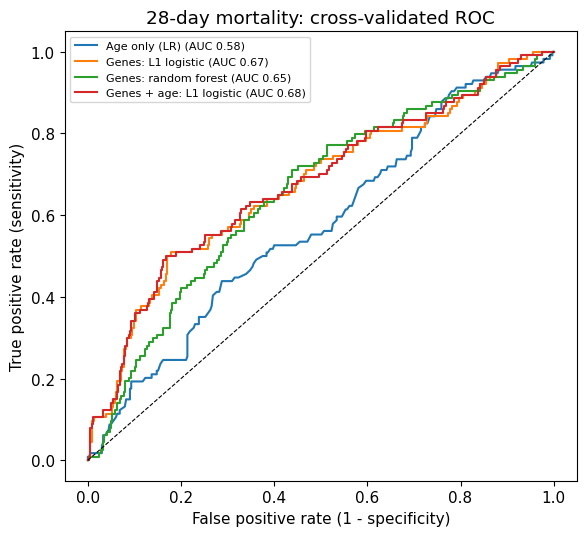

In [60]:
cv1 = StratifiedKFold(5, shuffle=True, random_state=1)
plt.figure(figsize=(6, 5.5))
for name in ["Age only (LR)", "Genes: L1 logistic", "Genes: random forest", "Genes + age: L1 logistic"]:
    m, Xm = models[name]
    prob = cross_val_predict(m, Xm, y, cv=cv1, method="predict_proba")[:, 1]
    fpr, tpr, _ = roc_curve(y, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y, prob):.2f})")
    if name == "Genes + age: L1 logistic":
        pred = (prob >= 0.5).astype(int)
        print("confusion matrix (rows = true survived/died):\n", confusion_matrix(y, pred))
        print(classification_report(y, pred, target_names=["survived", "died"], digits=3))
plt.plot([0, 1], [0, 1], "k--", lw=0.8); plt.xlabel("False positive rate (1 - specificity)"); plt.ylabel("True positive rate (sensitivity)")
plt.title("28-day mortality: cross-validated ROC"); plt.legend(fontsize=8); plt.tight_layout()
plt.savefig(os.path.join(FIG, "11_roc.png"), dpi=150); plt.show()

### 11.6 Which genes does the lasso keep? (interpretation only)

In [61]:
m, Xm = models["Genes: L1 logistic"]; m.fit(Xm, y)
selg = E.index[m.named_steps["selectkbest"].get_support()]
coef = pd.Series(m.named_steps["logisticregression"].coef_[0], index=selg)
coef = coef[coef != 0].sort_values()
print("non-zero genes:", len(coef))
print("protective (neg):", coef.head(8).index.tolist())
print("risk (pos):", coef.tail(8).index.tolist()[::-1])

non-zero genes: 19
protective (neg): ['ING4', 'TRIM27', 'TNFSF12', 'DENND2D', 'TNFRSF8', 'FAM38A', 'POC5', 'CX3CR1']
risk (pos): ['TUBG2', 'DAAM2', 'DDIT4', 'NCRNA00188', 'HSBP1L1', 'DEFA4', 'TSC22D3', 'ZNF862']


### 11.7 Is the gain over age real? Bootstrap CI, internal cross-hospital test, nested CV

In [62]:
ga_model, _ = models["Genes + age: L1 logistic"]; age_model, _ = models["Age only (LR)"]
p_ga = cross_val_predict(ga_model, Xgage, y, cv=cv1, method="predict_proba")[:, 1]
p_a = cross_val_predict(age_model, Xage, y, cv=cv1, method="predict_proba")[:, 1]
rng = np.random.default_rng(0); diffs = []
for _ in range(2000):
    i = rng.integers(0, len(y), len(y))
    diffs.append(roc_auc_score(y[i], p_ga[i]) - roc_auc_score(y[i], p_a[i]))
diffs = np.array(diffs)
print(f"AUROC genes+age {roc_auc_score(y, p_ga):.3f} vs age {roc_auc_score(y, p_a):.3f}; difference {diffs.mean():.3f}, "
      f"95% CI {np.percentile(diffs, 2.5):.3f} to {np.percentile(diffs, 97.5):.3f}, P(diff<=0) = {np.mean(diffs <= 0):.3f}")
SUMMARY["auc_diff"], SUMMARY["auc_diff_ci"] = diffs.mean(), (np.percentile(diffs, 2.5), np.percentile(diffs, 97.5))
tr = (sep.endotype_cohort == "discovery").values; te = ~tr; hold = {}
for name in ["Age only (LR)", "Genes: L1 logistic", "Genes + age: L1 logistic"]:
    m, Xm = models[name]; m.fit(Xm[tr], y[tr])
    hold[name] = roc_auc_score(y[te], m.predict_proba(Xm[te])[:, 1])
    print(f"Amsterdam -> Utrecht  {name:26s} AUROC = {hold[name]:.3f}")
SUMMARY["hold_gene"], SUMMARY["hold_age"] = hold["Genes: L1 logistic"], hold["Age only (LR)"]
grid = GridSearchCV(ga_model, {"pre__genes__selectkbest__k": [50, 200, 500], "clf__C": [0.02, 0.05, 0.2]},
                    cv=StratifiedKFold(5, shuffle=True, random_state=2), scoring="roc_auc", n_jobs=-1)
nested = cross_val_score(grid, Xgage, y, cv=StratifiedKFold(5, shuffle=True, random_state=3), scoring="roc_auc")
print(f"Nested CV (tuned k, C) AUROC = {nested.mean():.3f} +/- {nested.std():.3f}")
SUMMARY["nested"] = nested.mean()

AUROC genes+age 0.676 vs age 0.577; difference 0.100, 95% CI 0.019 to 0.178, P(diff<=0) = 0.007
Amsterdam -> Utrecht  Age only (LR)              AUROC = 0.592
Amsterdam -> Utrecht  Genes: L1 logistic         AUROC = 0.627
Amsterdam -> Utrecht  Genes + age: L1 logistic   AUROC = 0.627
Nested CV (tuned k, C) AUROC = 0.677 +/- 0.045


95% CI of the difference excludes 0 → **reject H0: genes add information over age.** The cross-hospital gain is smaller (realistic estimate; call it an *internal cross-hospital test*, not external validation). Nested CV ≈ fixed-setting CV → settings did not inflate the result.
### 11.9 Extra: the rest of the course's classifiers + bias–variance (exploratory, not ranked)

In [63]:
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
def sel(): return [StandardScaler(), SelectKBest(f_classif, k=200)]
extra = {
    "Genes: ridge (L2) logistic": make_pipeline(*sel(), LogisticRegression(penalty="l2", C=0.001, class_weight="balanced", max_iter=2000)),
    "Genes: elastic net logistic": make_pipeline(*sel(), LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.5, C=0.05, class_weight="balanced", max_iter=5000)),
    "Genes: Gaussian Naive Bayes": make_pipeline(*sel(), GaussianNB()),
    "Genes: kNN (k=25)": make_pipeline(*sel(), KNeighborsClassifier(n_neighbors=25)),
    "Genes: decision tree (depth 3)": make_pipeline(*sel(), DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, class_weight="balanced", random_state=0)),
    "Genes: gradient boosting": make_pipeline(*sel(), GradientBoostingClassifier(n_estimators=200, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=0)),
}
for name, m in extra.items():
    auc = cross_val_score(m, Xg, y, cv=cv, scoring="roc_auc", n_jobs=-1)
    print(f"{name:32s} AUROC = {auc.mean():.3f} +/- {auc.std():.3f}")
for name, m in [("Genes: decision tree (depth 3)", extra["Genes: decision tree (depth 3)"]),
                ("Genes: gradient boosting", extra["Genes: gradient boosting"]),
                ("Genes: random forest", models["Genes: random forest"][0])]:
    r = cross_validate(m, Xg, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc", return_train_score=True)
    print(f"{name:32s} train AUROC {r['train_score'].mean():.3f} | test AUROC {r['test_score'].mean():.3f}")

Genes: ridge (L2) logistic       AUROC = 0.668 +/- 0.061
Genes: elastic net logistic      AUROC = 0.677 +/- 0.060
Genes: Gaussian Naive Bayes      AUROC = 0.649 +/- 0.058
Genes: kNN (k=25)                AUROC = 0.665 +/- 0.065
Genes: decision tree (depth 3)   AUROC = 0.581 +/- 0.062
Genes: gradient boosting         AUROC = 0.634 +/- 0.066
Genes: decision tree (depth 3)   train AUROC 0.807 | test AUROC 0.615
Genes: gradient boosting         train AUROC 1.000 | test AUROC 0.629
Genes: random forest             train AUROC 0.999 | test AUROC 0.659


Regularised linear models do best; trees/boosting/forest overfit (train ≫ test). Performance is similar across methods, so **the limit is the information in the data**. Only the lasso was tuned, so don't rank algorithms.

# CHECKPOINT 2: results in one table (manual 21.3, filled from this run)

In [64]:
S = SUMMARY
rq = pd.DataFrame([
 ["RQ1 structure", "Healthy separate from critically ill; sepsis = continuum ordered by endotype", f"PC1+PC2 = {100*S['pc12_all']:.0f}% variance (all 802)"],
 ["RQ2 clusters", f"No sharp clusters (silhouette <= {S['sil_max']:.2f}, gap k = {S['gap_k']}); k=4 stable (subsample ARI {S['boot_ari']:.2f}); not batch-driven (R2 <= {S['batch_r2_max']:.3f}, p = {S['batch_p']:.2f})", "Steps 5, 9"],
 ["RQ3 mortality", f"C1 {100*S['c1_rate']:.0f}% vs lowest {100*S['c4_rate']:.0f}%", f"chi2 p = {S['chi2_p_k4']:.3f}, log-rank p = {S['logrank_p']:.3f}, HR {S['hr']:.2f} ({S['hr_lo']:.2f}-{S['hr_hi']:.2f})"],
 ["RQ4 genes", f"{S['n_de']} genes FDR<0.05 (died vs survived), {S['pct_down']:.0f}% down", f"Welch + BH; shuffled labels = {S['n_shuffled']}"],
 ["RQ5 pathways", f"Died up: {', '.join(S['gsea_up'])}; down: {', '.join(S['gsea_down'])}", "ORA (Fisher), GSEA"],
 ["RQ6 robustness", f"Concordant with Mars (ARI {S['ari_mars']:.2f} at 2,000 genes; {S['ari_mars_500']:.2f} at 500)", "Step 9"],
 ["RQ7 confounding", f"C1 OR {S['or_adj']:.2f} ({S['or_ci'][0]:.2f}-{S['or_ci'][1]:.2f}) after age + sex; {S['or_range'][0]:.2f}-{S['or_range'][1]:.2f} across models", "Logistic regression"],
 ["RQ8 prediction", f"Genes beat age: CV AUROC {S['auc_gene']:.2f} vs {S['auc_age']:.2f} (diff {S['auc_diff']:.2f}, 95% CI {S['auc_diff_ci'][0]:.2f}-{S['auc_diff_ci'][1]:.2f}); hold-out {S['hold_gene']:.2f} vs {S['hold_age']:.2f}; nested {S['nested']:.2f}", "Steps 11.3, 11.7"],
 ["Extra", f"PC1+PC2 predict death at least as well as discrete groups (AIC {S['aic_pc']:.0f} vs {S['aic_disc'][0]:.0f}-{S['aic_disc'][1]:.0f}; CV AUROC {S['cv_pc']:.2f} vs {S['cv_disc'][0]:.2f}-{S['cv_disc'][1]:.2f})", "Step 9.7"],
], columns=["RQ", "Answer", "Key evidence"])
rq.to_csv(os.path.join(RES, "checkpoint2_results_table.csv"), index=False)
with pd.option_context("display.max_colwidth", 200):
    display(rq)
mins, secs = divmod(time.time() - T0, 60)
print(f"Total run time for the whole notebook: {int(mins)} min {secs:.0f} s")

,RQ,Answer,Key evidence
0,RQ1 structure,Healthy separate from critically ill; sepsis = continuum ordered by endotype,PC1+PC2 = 37% variance (all 802)
1,RQ2 clusters,"No sharp clusters (silhouette <= 0.19, gap k = 1); k=4 stable (subsample ARI 0.83); not batch-driven (R2 <= 0.025, p = 0.90)","Steps 5, 9"
2,RQ3 mortality,C1 33% vs lowest 18%,"chi2 p = 0.043, log-rank p = 0.029, HR 1.66 (1.11-2.50)"
3,RQ4 genes,"680 genes FDR<0.05 (died vs survived), 83% down",Welch + BH; shuffled labels = 0
4,RQ5 pathways,"Died up: HEME_METABOLISM, E2F_TARGETS, HYPOXIA, CHOLESTEROL_HOMEOSTASIS; down: INTERFERON_ALPHA_RESPONSE, INTERFERON_GAMMA_RESPONSE, ALLOGRAFT_REJECTION, INFLAMMATORY_RESPONSE","ORA (Fisher), GSEA"
5,RQ6 robustness,"Concordant with Mars (ARI 0.31 at 2,000 genes; 0.62 at 500)",Step 9
6,RQ7 confounding,C1 OR 1.76 (1.07-2.88) after age + sex; 1.76-1.79 across models,Logistic regression
7,RQ8 prediction,"Genes beat age: CV AUROC 0.68 vs 0.58 (diff 0.10, 95% CI 0.02-0.18); hold-out 0.63 vs 0.59; nested 0.68","Steps 11.3, 11.7"
8,Extra,PC1+PC2 predict death at least as well as discrete groups (AIC 510 vs 517-519; CV AUROC 0.63 vs 0.60-0.62),Step 9.7


Total run time for the whole notebook: 8 min 8 s


## One-paragraph story (abstract draft, manual 21.4)
Using whole-blood transcriptomes of 479 ICU sepsis patients (GSE65682), we found no sharply separated clusters: silhouette, gap statistic, Calinski–Harabasz and DBSCAN all indicated a continuum. A 4-way k-means partition, made without outcome information, was stable under resampling, unaffected by array batch, and concordant with the published Mars endotypes. One cluster (C1), characterised by high haem metabolism and low inflammatory/IL-6 signalling and mostly Mars1, had markedly higher 28-day mortality, independent of age, sex, diabetes and hospital. Two continuous expression axes predicted death at least as well as any discrete grouping, including the published one. Non-survivors showed hundreds of differentially expressed genes (FDR < 0.05) with reduced interferon and lymphocyte signatures, and a lasso gene model predicted death better than age (see the table above for this run's exact numbers).

**Next (manual Step 12):** report (8 pages, Arial 11) using the figures in `figures/` and tables in `results/`; AI-use statement; push notebook + `ai_logs/` to GitHub.